# Banking77 with TinyLlama 1.1B
## Apple Silicon: MPS LoRA

    **DSS workshop lab.** Fine-tune an ungated, approximately 1.1-billion-parameter chat model
    to return one of Banking77's 77 intent names. This notebook is self-contained and replaces
    the earlier synthetic-data script. No API key is required for these public sources.

    ## Goal
    Prepare real intent data, inspect response-only loss masks, train adapters, and compare
    generated labels with a base-model baseline. Record accuracy, macro-F1 over all 77 intents,
    and valid-label rate. No improvement or timing result is assumed.

    **Before the workshop:** install dependencies, download the model, then run a two-step smoke
    test in a new run directory. A short workshop run demonstrates the process and is not a
    converged Banking77 benchmark. First model download is roughly 2.2 GB for the weight payload.
    Internet access is required for initial setup.

    **Execution status:** preprocessing and tokenizer checks can run without a GPU. Actual
    accelerator training has not been executed in the authoring environment. GPU training and
    model-generated results have intentionally empty outputs until you run them.


**Benchmark flow:** score the frozen baseline before training, train the adapter, then score the same validation queries and inspect changes. After choosing settings, run the paired full official-test benchmark. No improvement is assumed.

**Alternative training path:** section 15 trains a dedicated 77-way classification head, first by itself and then with LoRA. For a classifier-only run, execute sections 1–6 and shared helpers, then jump to section 15.

## How to read this annotated edition
Every executable source line has an explanatory comment immediately above it, including continuation lines and closing delimiters. Every function has a docstring describing its inputs, return value and important behavior. Docstring lines already explain themselves and do not have redundant `#` comments.

For PyTorch, read comments in this order: **tensor shape/device/dtype → forward pass → scalar loss → backward/gradient accumulation → unscale → clip → optimizer step → gradient reset**. `eval()` changes dropout behavior; `inference_mode()` changes autograd recording. Neither performs training. The class head and LoRA are different sets of trainable parameters. Existing results are retained; these annotations do not claim a new full GPU training run.

## Setup
Use Python 3.11 or 3.12 in a fresh notebook environment. Run the installation cell once, then **restart the kernel and run from the top**. Packages install into the active kernel. CUDA users should first choose a PyTorch build compatible with their driver.

This lab uses **PyTorch only**. The imports cell sets `USE_TF=0`, `USE_FLAX=0` and `USE_TORCH=1` before importing Transformers. This prevents an unrelated installed TensorFlow / `ml_dtypes` stack from causing the NumPy binary-compatibility error reported in section 7. Setting these variables after Transformers has loaded is too late: restart first.

If a NumPy binary-compatibility error still occurs in a package this lab actually uses, repair that package in the notebook environment. A compatibility fallback for Python 3.11/3.12 is `%pip install "numpy==1.26.4"`, followed by another kernel restart. Avoid changing your shared Miniforge base environment when a dedicated kernel is available.


In [ ]:
# Install these dependencies into the CURRENT Jupyter kernel environment; restart the kernel before importing the newly installed binary packages.
%pip install "torch>=2.4" "transformers>=4.45,<6" "peft>=0.13,<1" accelerate pandas scikit-learn matplotlib sentencepiece tqdm


### 1. Imports and parameters
    Change these settings before running the lab. `TRAIN_PER_INTENT=20` keeps every intent
    represented in a short exercise. Short default runs may not see every selected example.
    Set `FULL_TRAINING=True` to train across the full cleaned training pool for `EPOCHS` epochs.
    The validation set always comes from the official training file.


In [3]:
# Select the PyTorch backend BEFORE the first transformers / peft import.
# Import os for environment variables and process configuration.
import os
# Import sys for already-loaded module detection.
import sys
# Check "transformers" in sys.modules and os.environ.get("USE_TF") != "0" before entering this branch in
# notebook cell; execute the indented lines only when it is true.
if "transformers" in sys.modules and os.environ.get("USE_TF") != "0":
    # Stop this run rather than proceeding with an invalid setup. Restart the notebook kernel, then run from the
    # top so PyTorch-only settings take effect.
    raise RuntimeError("Restart the notebook kernel, then run from the top so PyTorch-only settings take effect.")
# Set this backend/environment option before framework imports; it controls initialization behavior rather
# than a model hyperparameter.
os.environ["USE_TF"] = "0"
# Set this backend/environment option before framework imports; it controls initialization behavior rather
# than a model hyperparameter.
os.environ["USE_FLAX"] = "0"
# Set this backend/environment option before framework imports; it controls initialization behavior rather
# than a model hyperparameter.
os.environ["USE_TORCH"] = "1"

# Import contextlib for no-op context managers on non-AMP paths.
import contextlib
# Import hashlib for SHA-256 dataset integrity checks.
import hashlib
# Import importlib.metadata for installed package version recording.
import importlib.metadata
# Import json for portable run manifests and label files.
import json
# Import math for ceil/rounding for lengths and update budgets.
import math
# Import os for environment variables and process configuration.
import os
# Import pathlib for filesystem paths.
from pathlib import Path
# Import platform for runtime architecture and OS metadata.
import platform
# Import random for Python-level seeded randomness.
import random
# Import time for monotonic wall-clock measurements.
import time
# Import urllib.request for pinned dataset downloads.
import urllib.request

# Import numpy for seeded sampling, numeric arrays and summary arithmetic.
import numpy as np
# Import pandas for dataset tables and CSV exports.
import pandas as pd
# Import matplotlib.pyplot for portable charts.
import matplotlib.pyplot as plt
# Import IPython.display for readable notebook table display.
from IPython.display import display
# Import sklearn.metrics for strict accuracy and fixed-label macro-F1.
from sklearn.metrics import accuracy_score, f1_score, classification_report
# Import tqdm.auto for notebook progress reporting.
from tqdm.auto import tqdm
# Set this backend/environment option before framework imports; it controls initialization behavior rather
# than a model hyperparameter.
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# Set this backend/environment option before framework imports; it controls initialization behavior rather
# than a model hyperparameter.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # before transformers / torch import
# Import transformers for tokenizers and pretrained model architectures.
from transformers import AutoTokenizer


In [4]:
# Choose the pretrained TinyLlama checkpoint shared by all experiments.
MODEL_ID = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
# Pin the exact model/tokenizer commit so upstream updates cannot silently alter the run.
MODEL_REVISION = "fe8a4ea1ffedaf415f4da2f062534de366a451e6"
# Choose ordinary LoRA or CUDA NF4 QLoRA; the MPS generative path supports ordinary LoRA.
METHOD = "lora"  # unquantized LoRA for this MPS lab
# Set the common random seed for data selection, initialization and training order; this alone does not
# guarantee bitwise device determinism.
SEED = 42
# Select the full cleaned training pool instead of the small workshop subset.
FULL_TRAINING = False       # True uses the full cleaned train pool and epoch count below
# Set full-pool passes used only when FULL_TRAINING derives the generative update budget.
EPOCHS = 1
# Cap selected training examples per intent; None keeps the full training pool.
TRAIN_PER_INTENT = 20       # None uses the full cleaned training pool
# Set held-out development examples per intent, separate from the official test.
VAL_PER_INTENT = 2          # 154 development evaluation examples
# Reserve this fraction within each cleaned training-source class for validation.
VALIDATION_FRACTION = 0.10
# Set generative optimizer updates, not epochs; each update processes GRAD_ACCUM examples.
MAX_STEPS = 30             # optimizer updates; use 2 for the first smoke test
# Accumulate this many microbatch gradients before one generative optimizer update.
GRAD_ACCUM = 2
# Set the low-rank adapter bottleneck width, which controls trainable adapter count.
RANK = 8
# Set the generative adapter optimizer learning rate, a starting setting rather than a measured optimum.
LEARNING_RATE = 2e-4
# Evaluate validation loss at this optimizer-update interval.
EVAL_EVERY = 20
# Cap generated answer length; the budget must fit every intent spelling plus EOS.
MAX_NEW_TOKENS = 24
# Keep official-test evaluation off until configuration choices are frozen.
RUN_FINAL_TEST = False      # set True only after all configuration choices are frozen
# Choose whether to release the training model and verify a saved generative adapter.
RELOAD_FOR_INFERENCE = False
# Locate local verified dataset files.
CACHE_DIR = Path("banking77_cache")
# Build a separate generative experiment directory from runtime, method and rank.
RUN_DIR = Path("runs/banking77_mps_" + METHOD + "_r" + str(RANK))
# Select explicit MPS weight precision; BF16 requires the runtime probe to succeed.
MPS_DTYPE = "float32"       # optional: "bfloat16" on a supported macOS/PyTorch stack
# Verify the stated invariant and stop if it fails: MAX_STEPS > 0 and GRAD_ACCUM > 0 and RANK > 0. Assertions
# check assumptions; they do not repair data or prove model quality.
assert MAX_STEPS > 0 and GRAD_ACCUM > 0 and RANK > 0
# Verify the stated invariant and stop if it fails: 0 < VALIDATION_FRACTION < 1. Assertions check assumptions;
# they do not repair data or prove model quality.
assert 0 < VALIDATION_FRACTION < 1
# Verify the stated invariant and stop if it fails: LEARNING_RATE > 0 and EVAL_EVERY > 0. Assertions check
# assumptions; they do not repair data or prove model quality.
assert LEARNING_RATE > 0 and EVAL_EVERY > 0
# Seed Python random operations; NumPy and Torch maintain separate generators that are seeded separately.
random.seed(SEED)
# Seed NumPy global sampling for reproducibility; local default_rng objects also receive their own seed.
np.random.seed(SEED)
# Set shared figure size, type size and unobtrusive axes for readable notebook charts; this does not affect
# training.
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11,
                     # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
                     # order/spelling for reproducible inputs or reporting.
                     "axes.spines.top": False, "axes.spines.right": False})


### 2. Load the original Banking77 files
    The original data has **10,003 training queries**, **3,080 test queries** and **77 intents**.
    Load the pinned original CSVs and verify their SHA-256 hashes. This avoids the deprecated
    dataset-script loader in older copies of `PolyAI/banking77`.

    Attribution: BANKING77 © PolyAI Limited, **CC BY 4.0**. Casanueva et al. (2020),
    [Efficient Intent Detection with Dual Sentence Encoders](https://arxiv.org/abs/2003.04807).
    [Original source files](https://github.com/PolyAI-LDN/task-specific-datasets/tree/master/banking_data).


In [5]:
# Pin the dataset repository commit.
DATA_REVISION = "9d081458ff52e53cf7e848f414e6e9344e4e6696"
# Construct download URLs from that pinned dataset commit.
DATA_BASE = f"https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/{DATA_REVISION}/banking_data"
# Record the expected digest of each pinned dataset file; verify bytes before trusting them.
EXPECTED_SHA256 = {
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    "train.csv": "b06e26ac675513959a63135f11b94ea7786ed02da65db93a5650d8838cbc664b",
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    "test.csv": "d12d6e3bc4c3103966ae786dc435913c0c563dfa328f5a3646d0e62cfeeb474d",
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    "categories.json": "53261da888122daf2d120d925458631d9619e15d82e56052e7a42e535ce32b63",
# Close the multi-line container or call begun above; this delimiter does not perform a separate training
# operation.
}
# Create the output/cache directory; parent creation and existing-directory behavior follow the explicit flags
# on this line.
CACHE_DIR.mkdir(parents=True, exist_ok=True)
# Define verified_file: Fetch a pinned dataset file and verify its SHA-256 before use.
def verified_file(name):
    """Fetch a pinned dataset file and verify its SHA-256 before use.

    Args:
        name (str): One key in EXPECTED_SHA256, such as train.csv.

    Returns:
        pathlib.Path: Verified local file in CACHE_DIR.

    Notes:
        Raises ValueError if downloaded or cached bytes differ from the pinned digest.
        Downloads only when missing; may raise network or filesystem errors.
    """
    # Build or select the local file path used by this operation.
    path = CACHE_DIR / name
    # Check not path.exists() before entering this branch in verified_file; execute the indented lines only when
    # it is true.
    if not path.exists():
        # Enter urllib.request.urlopen(f"{DATA_BASE}/{name}", timeout=60) as response for this indented operation; the
        # context manager restores its prior state on exit.
        with urllib.request.urlopen(f"{DATA_BASE}/{name}", timeout=60) as response:
            # Read the downloaded response body as bytes for digest verification.
            payload = response.read()
        # Check hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256[name] before entering this branch in
        # verified_file; execute the indented lines only when it is true.
        if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256[name]:
            # Stop this run rather than proceeding with an invalid setup. Unexpected download hash:
            raise ValueError(f"Unexpected download hash: {name}")
        # Write only the hash-verified downloaded bytes into the dataset cache.
        path.write_bytes(payload)
    # Check hashlib.sha256(path.read_bytes()).hexdigest() != EXPECTED_SHA256[name] before entering this branch in
    # verified_file; execute the indented lines only when it is true.
    if hashlib.sha256(path.read_bytes()).hexdigest() != EXPECTED_SHA256[name]:
        # Stop this run rather than proceeding with an invalid setup. Cached file changed:  . Remove it and rerun.
        raise ValueError(f"Cached file changed: {path}. Remove it and rerun.")
    # Return from verified_file. pathlib.Path: Verified local file in CACHE_DIR.
    return path

# Read the verified original training CSV, preserving literal text instead of converting strings to missing
# values.
raw_train = pd.read_csv(verified_file("train.csv"), keep_default_na=False)
# Read all official test rows without filtering or resampling them.
raw_test = pd.read_csv(verified_file("test.csv"), keep_default_na=False)
# Load the canonical 77-label order; this order defines every class-index mapping.
LABELS = json.loads(verified_file("categories.json").read_text())
# Verify the stated invariant and stop if it fails: len(LABELS) == len(set(LABELS)) == 77. Assertions check
# assumptions; they do not repair data or prove model quality.
assert len(LABELS) == len(set(LABELS)) == 77
# Verify the stated invariant and stop if it fails: len(raw_train) == 10003 and len(raw_test) == 3080.
# Assertions check assumptions; they do not repair data or prove model quality.
assert len(raw_train) == 10003 and len(raw_test) == 3080
# Verify the stated invariant and stop if it fails: set(raw_train.category) == set(raw_test.category) ==
# set(LABELS). Assertions check assumptions; they do not repair data or prove model quality.
assert set(raw_train.category) == set(raw_test.category) == set(LABELS)
# Verify the stated invariant and stop if it fails: raw_train.text.str.strip().ne("").all() and
# raw_test.text.str.strip().ne("").all(). Assertions check assumptions; they do not repair data or prove model
# quality.
assert raw_train.text.str.strip().ne("").all() and raw_test.text.str.strip().ne("").all()
# Report print(f"Original files: {len(raw_train):,} train, {len(raw_test):,} test, {len(LABELS)} intents") for
# inspection; printing does not change model weights or predictions.
print(f"Original files: {len(raw_train):,} train, {len(raw_test):,} test, {len(LABELS)} intents")
# Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
display(raw_train.head(3))


Original files: 10,003 train, 3,080 test, 77 intents


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival


### 3. Audit duplicates and create a validation split
    Normalize case and whitespace only for deduplication; preserve the original model inputs.
    Remove repeated training questions and training texts that also occur in the official test
    file. This is **text-only decontamination**, not tuning on test labels. Keep every official
    test row unchanged. The resulting experiment uses a cleaned training set, so report that
    preprocessing when comparing with published results.

    Split the remaining training pool within each intent, then take balanced workshop subsets.
    Persist source row indices so both notebooks can reproduce exactly the same data choices.


In [6]:
# Define normalized_text: Build a comparison key for exact-text deduplication.
def normalized_text(text):
    """Build a comparison key for exact-text deduplication.

    Args:
        text (str): Original customer query.

    Returns:
        str: Unicode-casefolded text with whitespace collapsed.

    Notes:
        This key never replaces the original model input. It detects normalized exact matches,
        not semantic near-duplicates.
    """
    # Return from normalized_text. str: Unicode-casefolded text with whitespace collapsed.
    return " ".join(text.casefold().split())

# Create/filter a working training table; preserve the official test file.
train_frame = raw_train.copy()
# Retain the original CSV row number before filtering so the selected split can be reconstructed later.
train_frame["source_row"] = np.arange(len(train_frame))
# Create normalized matching keys for duplicate checks while preserving each original query in text.
train_frame["text_key"] = train_frame.text.map(normalized_text)
# Collect normalized official-test texts for training-source decontamination.
test_keys = set(raw_test.text.map(normalized_text))
# Count distinct labels for each normalized training text to detect contradictory annotations.
conflicts = train_frame.groupby("text_key").category.nunique()
# Verify the stated invariant and stop if it fails: conflicts.max() == 1, "Conflicting labels need review
# before splitting.". Assertions check assumptions; they do not repair data or prove model quality.
assert conflicts.max() == 1, "Conflicting labels need review before splitting."
# Count repeated normalized training texts before removing them.
duplicate_count = int(train_frame.duplicated("text_key").sum())
# Create/filter a working training table; preserve the official test file.
train_frame = train_frame.drop_duplicates("text_key").copy()
# Count unique training texts that also occur in the official test text set.
overlap_count = int(train_frame.text_key.isin(test_keys).sum())
# Text-only decontamination. Official test labels and rows remain unchanged.
# Create/filter a working training table; preserve the official test file.
train_frame = train_frame.loc[~train_frame.text_key.isin(test_keys)].copy()

# Create a local seeded NumPy random generator so splitting/shuffling is reproducible.
rng = np.random.default_rng(SEED)
# Assign train_parts, val_parts from [], []. This value is reused by the following steps in notebook cell.
train_parts, val_parts = [], []
# Iterate label in LABELS in notebook cell; each iteration processes the indicated item without changing the
# enclosing experiment definition.
for label in LABELS:
    # Select the current intent subset or accumulation group; subsequent indexing uses these rows only.
    group = train_frame.loc[train_frame.category.eq(label)]
    # Construct or shuffle positional training indices so each pass has a randomized order.
    order = rng.permutation(len(group))
    # Reserve at least two validation examples for this intent without consuming its entire class.
    n_val = max(2, int(round(len(group) * VALIDATION_FRACTION)))
    # Verify the stated invariant and stop if it fails: n_val < len(group). Assertions check assumptions; they do
    # not repair data or prove model quality.
    assert n_val < len(group)
    # Append this record or partition to its collection in notebook cell; the surrounding fields describe what is
    # retained.
    val_parts.append(group.iloc[order[:n_val]])
    # Append this record or partition to its collection in notebook cell; the surrounding fields describe what is
    # retained.
    train_parts.append(group.iloc[order[n_val:]])
# Combine cleaned per-intent training partitions into one indexed pool.
train_pool = pd.concat(train_parts).reset_index(drop=True)
# Combine validation-only partitions drawn from the training-source file.
validation_pool = pd.concat(val_parts).reset_index(drop=True)

# Define balanced_subset: Select a seeded per-intent subset and shuffle its row order.
def balanced_subset(frame, per_intent, seed=SEED):
    """Select a seeded per-intent subset and shuffle its row order.

    Args:
        frame (DataFrame): Candidate rows with category. per_intent (int or None): Maximum
        rows per label, or all rows. seed (int): Sampling seed.

    Returns:
        DataFrame: Selected rows with a fresh positional index.

    Notes:
        Raises ValueError for nonpositive per_intent. Uses the global LABELS catalog; a small
        class contributes its available rows.
    """
    # Check per_intent is None before entering this branch in balanced_subset; execute the indented lines only
    # when it is true.
    if per_intent is None:
        # Return from balanced_subset. DataFrame: Selected rows with a fresh positional index.
        return frame.sample(frac=1, random_state=seed).reset_index(drop=True)
    # Check per_intent < 1 before entering this branch in balanced_subset; execute the indented lines only when it
    # is true.
    if per_intent < 1:
        # Stop this run rather than proceeding with an invalid setup. per_intent must be positive or None
        raise ValueError("per_intent must be positive or None")
    # Collect per-class samples or optimizer parameter groups; each group can carry its own learning rate.
    groups = [frame.loc[frame.category.eq(label)].sample(
        # Assign n from min(per_intent, int(frame.category.eq(label).sum())), random_state=seed). This value is reused
        # by the following steps in balanced_subset.
        n=min(per_intent, int(frame.category.eq(label).sum())), random_state=seed)
        # Iterate label in LABELS] in balanced_subset; each iteration processes the indicated item without changing
        # the enclosing experiment definition.
        for label in LABELS]
    # Return from balanced_subset. DataFrame: Selected rows with a fresh positional index.
    return pd.concat(groups).sample(frac=1, random_state=seed).reset_index(drop=True)

# Select the actual training rows for this experiment.
train_data = balanced_subset(train_pool, None if FULL_TRAINING else TRAIN_PER_INTENT)
# Check FULL_TRAINING before entering this branch in notebook cell; execute the indented lines only when it is
# true.
if FULL_TRAINING:
    # Set generative optimizer updates, not epochs; each update processes GRAD_ACCUM examples.
    MAX_STEPS = math.ceil(len(train_data) / GRAD_ACCUM) * EPOCHS
# Select the fixed balanced development-evaluation rows.
val_data = balanced_subset(validation_pool, VAL_PER_INTENT)
# Verify the stated invariant and stop if it fails:
# set(train_pool.text_key).isdisjoint(validation_pool.text_key). Assertions check assumptions; they do not
# repair data or prove model quality.
assert set(train_pool.text_key).isdisjoint(validation_pool.text_key)
# Verify the stated invariant and stop if it fails: set(train_pool.text_key).isdisjoint(test_keys). Assertions
# check assumptions; they do not repair data or prove model quality.
assert set(train_pool.text_key).isdisjoint(test_keys)
# Verify the stated invariant and stop if it fails: set(validation_pool.text_key).isdisjoint(test_keys).
# Assertions check assumptions; they do not repair data or prove model quality.
assert set(validation_pool.text_key).isdisjoint(test_keys)
# Verify the stated invariant and stop if it fails: set(train_data.category) == set(val_data.category) ==
# set(LABELS). Assertions check assumptions; they do not repair data or prove model quality.
assert set(train_data.category) == set(val_data.category) == set(LABELS)
# Record source-row membership and text-cleaning decisions for reproducible split reconstruction.
split_manifest = {
    # Record dataset_revision: pinned dataset commit; seed: random seed.
    "dataset_revision": DATA_REVISION, "seed": SEED,
    # Record normalization: text-key normalization used only for duplicate detection.
    "normalization": "Unicode casefold and whitespace collapse",
    # Record duplicate_training_rows_removed: count of repeated normalized training queries removed.
    "duplicate_training_rows_removed": duplicate_count,
    # Record test_overlapping_training_texts_removed: count of normalized test-overlapping texts removed from the
    # training source.
    "test_overlapping_training_texts_removed": overlap_count,
    # Record train_source_rows: original CSV row IDs selected for training.
    "train_source_rows": train_data.source_row.astype(int).tolist(),
    # Record validation_source_rows: original CSV row IDs reserved for development evaluation.
    "validation_source_rows": val_data.source_row.astype(int).tolist(),
    # Record official_test_rows: unchanged final-test row count.
    "official_test_rows": len(raw_test),
# Close the multi-line container or call begun above; this delimiter does not perform a separate training
# operation.
}
# Report print(f"Removed {duplicate_count} repeated training texts and {overlap_count} train/test text overla
# for inspection; printing does not change model weights or predictions.
print(f"Removed {duplicate_count} repeated training texts and {overlap_count} train/test text overlaps.")
# Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
display(pd.DataFrame({
    # Specify split: the named value retained in this data/configuration record.
    "split": ["training pool", "validation pool", "workshop train", "workshop validation", "official test"],
    # Specify rows: the named value retained in this data/configuration record.
    "rows": [len(train_pool), len(validation_pool), len(train_data), len(val_data), len(raw_test)],
    # Specify purpose: the named value retained in this data/configuration record.
    "purpose": ["training source", "tuning source", "short training run", "development evaluation", "final evaluation only"],
# Close the multi-line container or call begun above; this delimiter does not perform a separate training
# operation.
}))


Removed 4 repeated training texts and 7 train/test text overlaps.


,split,rows,purpose
0,training pool,8992,training source
1,validation pool,1000,tuning source
2,workshop train,1540,short training run
3,workshop validation,154,development evaluation
4,official test,3080,final evaluation only


### 4. Inspect class coverage
    The chart previews the 12 most frequent intents in the original training file. The workshop
    subsets below it must cover all 77 intents. This is a data check, not a model result.


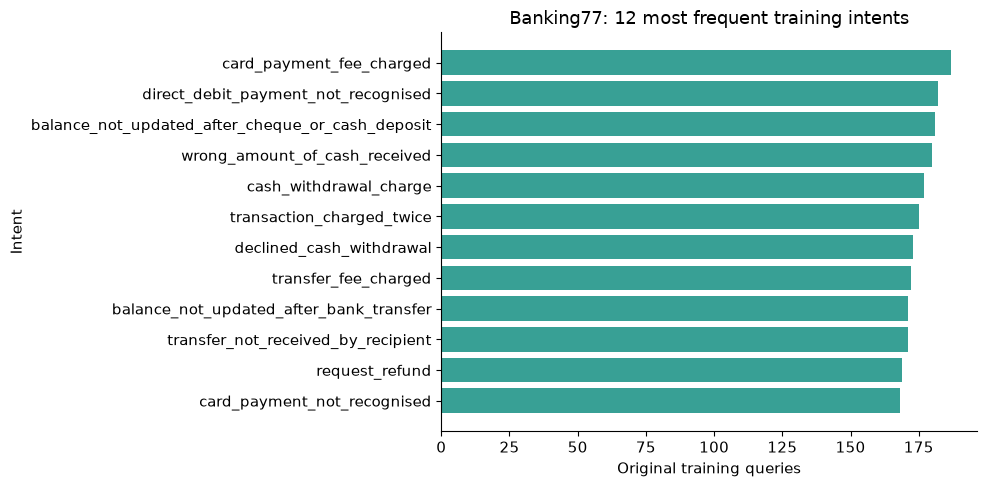

,train,validation
count,77.0,77.0
mean,20.0,2.0
std,0.0,0.0
min,20.0,2.0
25%,20.0,2.0
50%,20.0,2.0
75%,20.0,2.0
max,20.0,2.0


In [7]:
# Count the most frequent original intents and sort them for the coverage chart.
counts = raw_train.category.value_counts().nlargest(12).sort_values()
# Create a Matplotlib figure and axis for the next report.
fig, ax = plt.subplots(figsize=(10, 5))
# Configure/draw this part of the results figure: ax.barh(counts.index, counts.values, color="#38A095"). This
# changes presentation, not the underlying scoring.
ax.barh(counts.index, counts.values, color="#38A095")
# Configure/draw this part of the results figure: ax.set(title="Banking77: 12 most frequent training
# intents",. This changes presentation, not the underlying scoring.
ax.set(title="Banking77: 12 most frequent training intents",
       # Assign xlabel from "Original training queries", ylabel="Intent"). This value is reused by the following
       # steps in notebook cell.
       xlabel="Original training queries", ylabel="Intent")
# Configure/draw this part of the results figure: ax.set_xlim(left=0). This changes presentation, not the
# underlying scoring.
ax.set_xlim(left=0)
# Adjust subplot spacing to keep titles, labels and legends inside the figure.
fig.tight_layout()
# Render the prepared figure in the notebook output; this does not run inference or recompute metrics.
plt.show()
# Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
display(pd.DataFrame({"train": train_data.category.value_counts(),
                      # Specify validation: the named value retained in this data/configuration record.
                      "validation": val_data.category.value_counts()}).describe())


## Steps
    ### 5. Define the task and the assistant-only loss mask
    Both models see the identical list of valid intent names. The answer copies the upstream
    spelling exactly, including names such as `Refund_not_showing_up` and `reverted_card_payment?`.
    Do not lowercase labels or infer IDs from another dataset's ordering.

    Train only on assistant answer tokens and the final EOS token. Mask system, user and padding
    positions with `-100`. The code checks the token boundary and refuses silent truncation. It drops only trailing template whitespace after the final EOS.


In [8]:
# Preserve the upstream category spelling, punctuation and capitalization.
# The same full label catalog is visible to both the base and adapted model.
# Define the shared generative task instruction and complete valid-label catalog.
SYSTEM_PROMPT = (
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    "Classify the banking customer's intent. Return exactly one category name "
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    "from this list, copied verbatim. Do not explain.\n\n" + "\n".join(LABELS)
# Close the multi-line container or call begun above; this delimiter does not perform a separate training
# operation.
)
# Define prompt_messages: Construct the generative baseline/adapter input conversation.
def prompt_messages(text):
    """Construct the generative baseline/adapter input conversation.

    Args:
        text (str): Customer query.

    Returns:
        list[dict]: System turn with the shared label catalog, then user turn.

    Notes:
        Uses global SYSTEM_PROMPT. No assistant answer is included, preventing target leakage
        at inference.
    """
    # Return from prompt_messages. list[dict]: System turn with the shared label catalog, then user turn.
    return [{"role": "system", "content": SYSTEM_PROMPT},
            # Supply this literal/list/dictionary entry to the enclosing expression in prompt_messages; keep its
            # order/spelling for reproducible inputs or reporting.
            {"role": "user", "content": str(text)}]

# Define encode_example: Tokenize a generative training example and mask prompt/padding targets.
def encode_example(text, category, tokenizer, max_length=None):
    """Tokenize a generative training example and mask prompt/padding targets.

    Args:
        text (str): Query. category (str): Exact target intent. tokenizer: Pinned chat
        tokenizer. max_length (int or None): Fixed padded length.

    Returns:
        dict: input_ids, attention_mask and labels, each a list of equal length.

    Notes:
        Raises ValueError on changed template boundaries, missing answer/EOS or overflow.
        Labels use -100 for ignored positions; attention and loss masks have different jobs.
        Keeps answer EOS and removes only trailing template whitespace.
    """
    # Construct system/user turns without including the target answer.
    messages = prompt_messages(text)
    # Tokenize the prompt prefix including the marker where an assistant answer begins.
    prompt_ids = tokenizer.apply_chat_template(
        # Assign messages, tokenize from True, add_generation_prompt=True, return_dict=True)["input_ids"]. This value
        # is reused by the following steps in encode_example.
        messages, tokenize=True, add_generation_prompt=True, return_dict=True)["input_ids"]
    # Construct or trim the tokenized training sequence containing prompt, target and answer-ending EOS.
    full_ids = tokenizer.apply_chat_template(
        # Append the reviewed assistant intent to the training conversation; inference receives only the prompt
        # prefix.
        messages + [{"role": "assistant", "content": category}],
        # Assign tokenize from True, add_generation_prompt=False, return_dict=True)["input_ids"]. This value is reused
        # by the following steps in encode_example.
        tokenize=True, add_generation_prompt=False, return_dict=True)["input_ids"]
    # TinyLlama renders a newline after EOS. Keep the answer ending, drop only
    # the trailing template whitespace so the supervised completion ends at EOS.
    # Find the final EOS position, with -1 indicating a missing response ending.
    final_eos = max((i for i, token in enumerate(full_ids)
                     # Check token == tokenizer.eos_token_id), default=-1) before entering this branch in encode_example; execute
                     # the indented lines only when it is true.
                     if token == tokenizer.eos_token_id), default=-1)
    # Construct or trim the tokenized training sequence containing prompt, target and answer-ending EOS.
    full_ids = full_ids[:final_eos + 1]
    # Check full_ids[:len(prompt_ids)] != prompt_ids before entering this branch in encode_example; execute the
    # indented lines only when it is true.
    if full_ids[:len(prompt_ids)] != prompt_ids:
        # Stop this run rather than proceeding with an invalid setup. Chat-template token boundary changed. Inspect
        # the prefix before training.
        raise ValueError("Chat-template token boundary changed. Inspect the prefix before training.")
    # Check len(full_ids) <= len(prompt_ids) or full_ids[-1] != tokenizer.eos_token_id before entering this branch
    # in encode_example; execute the indented lines only when it is true.
    if len(full_ids) <= len(prompt_ids) or full_ids[-1] != tokenizer.eos_token_id:
        # Stop this run rather than proceeding with an invalid setup. Completion or end-of-turn supervision is
        # missing.
        raise ValueError("Completion or end-of-turn supervision is missing.")
    # Check max_length is not None and len(full_ids) > max_length before entering this branch in encode_example;
    # execute the indented lines only when it is true.
    if max_length is not None and len(full_ids) > max_length:
        # Stop this run rather than proceeding with an invalid setup. Example exceeds the configured context. Increase
        # it; never truncate targets silently.
        raise ValueError("Example exceeds the configured context. Increase it; never truncate targets silently.")
    # Compute how many right-padding positions are required to reach the fixed input length.
    pad = 0 if max_length is None else max_length - len(full_ids)
    # Return from encode_example. dict: input_ids, attention_mask and labels, each a list of equal length.
    return {
        # Specify input_ids: token IDs consumed by the embedding lookup.
        "input_ids": full_ids + [tokenizer.pad_token_id] * pad,
        # Specify attention_mask: 1 for real tokens and 0 for padding, controlling attention rather than direct loss
        # targets.
        "attention_mask": [1] * len(full_ids) + [0] * pad,
        # Specify labels: supervised targets; token IDs/-100 in the generative path, a scalar class ID in the
        # classifier path.
        "labels": [-100] * len(prompt_ids) + full_ids[len(prompt_ids):] + [-100] * pad,
    # Close the multi-line container or call begun above; this delimiter does not perform a separate training
    # operation.
    }


### 6. Tokenize and verify one batch
    Load only the pinned tokenizer here. A complete 77-label catalog consumes context, so derive
    a fixed sequence length from the selected train/validation examples, rounded to 64 tokens.
    This is intentionally a generative classification lab. An encoder classifier or a dedicated
    classification head may be more efficient for production intent routing.


In [9]:
# Assign tokenizer from AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION). This value is reused
# by the following steps in notebook cell.
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION)
# Check tokenizer.pad_token_id is None before entering this branch in notebook cell; execute the indented
# lines only when it is true.
if tokenizer.pad_token_id is None:
    # Assign tokenizer.pad_token from tokenizer.eos_token. This value is reused by the following steps in notebook
    # cell.
    tokenizer.pad_token = tokenizer.eos_token
# Assign tokenizer.padding_side from "right". This value is reused by the following steps in notebook cell.
tokenizer.padding_side = "right"

# Encode selected training rows without padding so the actual maximum length can be measured.
unpadded_train = [encode_example(r.text, r.category, tokenizer)
                  # Iterate r in train_data.itertuples()] in notebook cell; each iteration processes the indicated item without
                  # changing the enclosing experiment definition.
                  for r in train_data.itertuples()]
# Encode selected validation rows using the same token contract.
unpadded_val = [encode_example(r.text, r.category, tokenizer)
                # Iterate r in val_data.itertuples()] in notebook cell; each iteration processes the indicated item without
                # changing the enclosing experiment definition.
                for r in val_data.itertuples()]
# Find the longest complete prompt/answer sequence across the selected development data.
observed_max = max(len(row["input_ids"]) for row in unpadded_train + unpadded_val)
# Fixed training shapes limit graph-cache growth on MPS. Use the same rule on CUDA.
# Round the observed full-chat length up to a multiple of 64 for fixed training shapes.
SEQUENCE_LENGTH = math.ceil(observed_max / 64) * 64
# Check SEQUENCE_LENGTH > 2048 before entering this branch in notebook cell; execute the indented lines only
# when it is true.
if SEQUENCE_LENGTH > 2048:
    # Stop this run rather than proceeding with an invalid setup. The complete prompt exceeds TinyLlama's
    # 2,048-token context.
    raise ValueError("The complete prompt exceeds TinyLlama's 2,048-token context.")
# Build fixed-length generative training rows with response-only labels.
encoded_train = [encode_example(r.text, r.category, tokenizer, SEQUENCE_LENGTH)
                 # Iterate r in train_data.itertuples()] in notebook cell; each iteration processes the indicated item without
                 # changing the enclosing experiment definition.
                 for r in train_data.itertuples()]
# Build validation rows with the same prompt and label-masking rules.
encoded_val = [encode_example(r.text, r.category, tokenizer, SEQUENCE_LENGTH)
               # Iterate r in val_data.itertuples()] in notebook cell; each iteration processes the indicated item without
               # changing the enclosing experiment definition.
               for r in val_data.itertuples()]
# Extract non--100 target positions to inspect the actual supervised continuation.
supervised_ids = [i for i in encoded_train[0]["labels"] if i != -100]
# Verify the stated invariant and stop if it fails: MAX_NEW_TOKENS >= max(len(tokenizer(label,
# add_special_tokens=False)["input_ids"]) + 1 for label in LABELS). Assertions check assumptions; they do not
# repair data or prove model quality.
assert MAX_NEW_TOKENS >= max(len(tokenizer(label, add_special_tokens=False)["input_ids"]) + 1 for label in LABELS)
# Report print("Fixed training sequence length:", SEQUENCE_LENGTH) for inspection; printing does not change
# model weights or predictions.
print("Fixed training sequence length:", SEQUENCE_LENGTH)
# Report print("Supervised continuation:", repr(tokenizer.decode(supervised_ids))) for inspection; printing
# does not change model weights or predictions.
print("Supervised continuation:", repr(tokenizer.decode(supervised_ids)))
# Verify the stated invariant and stop if it fails:
# tokenizer.decode(supervised_ids).endswith(tokenizer.eos_token). Assertions check assumptions; they do not
# repair data or prove model quality.
assert tokenizer.decode(supervised_ids).endswith(tokenizer.eos_token)
# Verify the stated invariant and stop if it fails: all(len(r["input_ids"]) == SEQUENCE_LENGTH for r in
# encoded_train). Assertions check assumptions; they do not repair data or prove model quality.
assert all(len(r["input_ids"]) == SEQUENCE_LENGTH for r in encoded_train)
# Verify the stated invariant and stop if it fails: all(any(i != -100 for i in r["labels"]) for r in
# encoded_train). Assertions check assumptions; they do not repair data or prove model quality.
assert all(any(i != -100 for i in r["labels"]) for r in encoded_train)
# Verify the stated invariant and stop if it fails: all(label == -100 for r in encoded_train. Assertions check
# assumptions; they do not repair data or prove model quality.
assert all(label == -100 for r in encoded_train
           # Iterate label, mask in zip(r["labels"], r["attention_mask"]) if mask == 0) in notebook cell; each iteration
           # processes the indicated item without changing the enclosing experiment definition.
           for label, mask in zip(r["labels"], r["attention_mask"]) if mask == 0)


KeyboardInterrupt: 

### Shared scoring helpers
These define metrics and paired reports for both the generative and classification-head paths. They do not load a model.

### Hugging Face Hub Authentication

The model is public, so authentication is optional. Without a token, the Hugging Face Hub may warn that requests are unauthenticated or apply lower rate limits. To authenticate, create a read token in your Hugging Face account, then run this in the terminal that launches the notebook kernel:

```sh
export HF_TOKEN="hf_your_read_token"
```

Restart the notebook kernel after setting the variable. Do not commit a real token or put it in this notebook.

In [ ]:
# Map each canonical label to an integer for strict metric computation.
LABEL_TO_ID = {label: i for i, label in enumerate(LABELS)}

# Define summarize_predictions: Compute strict accuracy, fixed-77-label macro-F1 and output validity.
def summarize_predictions(frame):
    """Compute strict accuracy, fixed-77-label macro-F1 and output validity.

    Args:
        frame (DataFrame): expected and predicted intent strings in paired rows.

    Returns:
        dict: n, accuracy, macro_f1_77_intents and valid_label_rate.

    Notes:
        Uses LABEL_TO_ID and LABELS. Invalid prediction strings map to -1 and remain errors;
        no fuzzy correction is applied. Expected labels must belong to the catalog.
    """
    # Convert reviewed expected intent strings to integer IDs.
    y_true = [LABEL_TO_ID[x] for x in frame.expected]
    # Invalid text stays an error, rather than being fuzzy-matched to a label.
    # Convert predictions to IDs, preserving invalid text as -1 so it counts as wrong.
    y_pred = [LABEL_TO_ID.get(x, -1) for x in frame.predicted]
    # Return from summarize_predictions. dict: n, accuracy, macro_f1_77_intents and valid_label_rate.
    return {
        # Specify n: the requested number of rows sampled from this intent.
        "n": len(frame),
        # Specify accuracy: the named value retained in this data/configuration record.
        "accuracy": float(accuracy_score(y_true, y_pred)),
        # Specify macro_f1_77_intents: the named value retained in this data/configuration record.
        "macro_f1_77_intents": float(f1_score(
            # Assign y_true, y_pred, labels from list(range(77)), average="macro", zero_division=0)),. This value is
            # reused by the following steps in summarize_predictions.
            y_true, y_pred, labels=list(range(77)), average="macro", zero_division=0)),
        # Specify valid_label_rate: the named value retained in this data/configuration record.
        "valid_label_rate": float(frame.predicted.isin(LABELS).mean()),
    # Close the multi-line container or call begun above; this delimiter does not perform a separate training
    # operation.
    }


In [ ]:
# Name the task metrics shown in paired benchmark tables and charts.
QUALITY_METRICS = {
    # Specify accuracy: the named value retained in this data/configuration record.
    "accuracy": "Exact accuracy",
    # Specify macro_f1_77_intents: the named value retained in this data/configuration record.
    "macro_f1_77_intents": "Macro-F1 (77 intents)",
    # Specify valid_label_rate: the named value retained in this data/configuration record.
    "valid_label_rate": "Valid-label rate",
# Close the multi-line container or call begun above; this delimiter does not perform a separate training
# operation.
}

# Define benchmark_models: Compare two prediction sets on exactly the same ordered examples.
def benchmark_models(base_predictions, tuned_predictions, split_name, output_dir=None):
    """Compare two prediction sets on exactly the same ordered examples.

    Args:
        base_predictions, tuned_predictions (DataFrame): text, expected, predicted columns.
        split_name (str): Report/file prefix. output_dir (Path or None): Destination, default
        RUN_DIR.

    Returns:
        tuple: Summary DataFrame, paired predictions, per-intent DataFrame.

    Notes:
        Raises ValueError on empty, unequal or mismatched rows. Displays
        scores/chart/fixes/regressions and writes CSV/PNG files. Deltas are percentage points;
        absent per-intent support stays NaN rather than becoming a zero accuracy.
    """
    # Assign output_dir from RUN_DIR if output_dir is None else Path(output_dir). This value is reused by the
    # following steps in benchmark_models.
    output_dir = RUN_DIR if output_dir is None else Path(output_dir)
    # Reset baseline row indices to compare examples position by position.
    base = base_predictions.reset_index(drop=True)
    # Reset adapted row indices to the same positional convention.
    tuned = tuned_predictions.reset_index(drop=True)
    # Check base.empty or len(base) != len(tuned) before entering this branch in benchmark_models; execute the
    # indented lines only when it is true.
    if base.empty or len(base) != len(tuned):
        # Stop this run rather than proceeding with an invalid setup. Benchmark needs nonempty, equal-size prediction
        # sets.
        raise ValueError("Benchmark needs nonempty, equal-size prediction sets.")
    # Check not base[["text", "expected"]].equals(tuned[["text", "expected"]]) before entering this branch in
    # benchmark_models; execute the indented lines only when it is true.
    if not base[["text", "expected"]].equals(tuned[["text", "expected"]]):
        # Stop this run rather than proceeding with an invalid setup. Baseline and fine-tuned rows or targets differ.
        raise ValueError("Baseline and fine-tuned rows or targets differ.")
    # Calculate baseline quality metrics from its raw predictions.
    base_scores = summarize_predictions(base)
    # Calculate fine-tuned quality metrics with the identical definitions.
    tuned_scores = summarize_predictions(tuned)
    # Assemble exact metric values and fine-tuned-minus-baseline percentage-point changes.
    summary = pd.DataFrame([
        # Record Metric: human-readable metric name; Baseline (%): baseline score as a percentage.
        {"Metric": label, "Baseline (%)": 100 * base_scores[key],
         # Record Fine-tuned (%): adapted score as a percentage.
         "Fine-tuned (%)": 100 * tuned_scores[key],
         # Record Change (pp): percentage-point score difference.
         "Change (pp)": 100 * (tuned_scores[key] - base_scores[key])}
        # Iterate key, label in QUALITY_METRICS.items() in benchmark_models; each iteration processes the indicated
        # item without changing the enclosing experiment definition.
        for key, label in QUALITY_METRICS.items()
    # Finish building the metric summary table and use metric names as its lookup index.
    ]).set_index("Metric")
    # Build a per-query audit table retaining the text and expected intent.
    paired = base[["text", "expected"]].copy()
    # Retain every raw baseline answer in the paired-example audit table.
    paired["baseline_output"] = base.predicted
    # Retain the corresponding fine-tuned answer for direct row-by-row comparison.
    paired["fine_tuned_output"] = tuned.predicted
    # Compute a Boolean exact-match flag for each baseline answer against its reviewed label.
    paired["baseline_correct"] = base.predicted.eq(base.expected)
    # Compute the same exact-match flag for each adapted answer.
    paired["fine_tuned_correct"] = tuned.predicted.eq(tuned.expected)
    # Classify paired correctness changes using ordered Boolean conditions: fixed, regressed, both correct,
    # otherwise both wrong.
    paired["outcome"] = np.select([
        # Mark a fix: the baseline was wrong and the adapted model is correct; ~ negates and & combines Boolean Series
        # elementwise.
        ~paired.baseline_correct & paired.fine_tuned_correct,
        # Mark a regression: an originally correct baseline answer becomes wrong after adaptation.
        paired.baseline_correct & ~paired.fine_tuned_correct,
        # Mark queries both models answer correctly; they contribute no net change in accuracy.
        paired.baseline_correct & paired.fine_tuned_correct,
    # Assign these outcome names to the three masks; queries satisfying none of them are both wrong.
    ], ["Fixed by fine-tuning", "Regression", "Both correct"], default="Both wrong")
    # Define the exhaustive, mutually exclusive fix/regression/correct/wrong outcome order.
    outcome_order = ["Fixed by fine-tuning", "Regression", "Both correct", "Both wrong"]
    # Count all paired outcomes, explicitly retaining categories with zero examples.
    outcomes = paired.outcome.value_counts().reindex(outcome_order, fill_value=0)
    # Start collecting supported per-intent diagnostic statistics.
    intent_rows = []
    # Iterate label in LABELS in benchmark_models; each iteration processes the indicated item without changing
    # the enclosing experiment definition.
    for label in LABELS:
        # Select evaluation rows with the current reviewed intent.
        subset = paired.loc[paired.expected.eq(label)]
        # Record intent: canonical intent name; support: number of reviewed examples for this intent.
        intent_rows.append({"intent": label, "support": len(subset),
            # Record baseline_accuracy_pct: baseline correct fraction converted to percent.
            "baseline_accuracy_pct": 100 * subset.baseline_correct.mean() if len(subset) else np.nan,
            # Record fine_tuned_accuracy_pct: adapted correct fraction converted to percent.
            "fine_tuned_accuracy_pct": 100 * subset.fine_tuned_correct.mean() if len(subset) else np.nan})
    # Build the per-intent support/accuracy report.
    per_intent = pd.DataFrame(intent_rows)
    # Subtract the baseline per-intent percentage from the adapted percentage; preserve NaN for unsupported
    # intents.
    per_intent["change_pp"] = per_intent.fine_tuned_accuracy_pct - per_intent.baseline_accuracy_pct
    # Report print(f"{split_name}: {len(paired):,} identical queries, all {len(LABELS)} labels in the scoring cat
    # for inspection; printing does not change model weights or predictions.
    print(f"{split_name}: {len(paired):,} identical queries, all {len(LABELS)} labels in the scoring catalog.")
    # Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
    display(summary.round(2))
    # Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
    display(outcomes.rename("Queries").to_frame())
    # Create a Matplotlib figure and axis for the next report.
    fig, ax = plt.subplots(figsize=(9, 4.8))
    # Position metric groups along the plot axis.
    x = np.arange(len(summary)); width = 0.36
    # Iterate offset, column, color, hatch in [(-width/2, "Baseline (%)", "#60616A", "//"), in benchmark_models;
    # each iteration processes the indicated item without changing the enclosing experiment definition.
    for offset, column, color, hatch in [(-width/2, "Baseline (%)", "#60616A", "//"),
                                         # Offset the adapted-model bars to the right within each metric group, using a stable color and no baseline
                                         # hatch.
                                         (width/2, "Fine-tuned (%)", "#168B80", "")]:
        # Draw one model series with visible bar heights, color and hatch encoding.
        bars = ax.bar(x + offset, summary[column], width, label=column[:-4], color=color, hatch=hatch)
        # Configure/draw this part of the results figure: ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=10). This
        # changes presentation, not the underlying scoring.
        ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=10)
    # Configure/draw this part of the results figure: ax.set_xticks(x, summary.index). This changes presentation,
    # not the underlying scoring.
    ax.set_xticks(x, summary.index)
    # Configure/draw this part of the results figure: ax.set_ylim(0, 110). This changes presentation, not the
    # underlying scoring.
    ax.set_ylim(0, 110)
    # Configure/draw this part of the results figure: ax.set_yticks(np.arange(0, 101, 20)). This changes
    # presentation, not the underlying scoring.
    ax.set_yticks(np.arange(0, 101, 20))
    # Configure/draw this part of the results figure: ax.set_ylabel("Score (%)"). This changes presentation, not
    # the underlying scoring.
    ax.set_ylabel("Score (%)")
    # Configure/draw this part of the results figure: ax.set_title(f"Baseline vs fine-tuned: {split_name}
    # (n={len(paired):,})"). This changes presentation, not the underlying scoring.
    ax.set_title(f"Baseline vs fine-tuned: {split_name} (n={len(paired):,})")
    # Configure/draw this part of the results figure: ax.legend(loc="upper left", bbox_to_anchor=(0, -0.16),
    # ncol=2, frameon=False). This changes presentation, not the underlying scoring.
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.16), ncol=2, frameon=False)
    # Adjust subplot spacing to keep titles, labels and legends inside the figure.
    fig.tight_layout()
    # Choose the PNG destination for this split report.
    figure_path = output_dir / f"{split_name}_benchmark.png"
    # Create the output/cache directory; parent creation and existing-directory behavior follow the explicit flags
    # on this line.
    output_dir.mkdir(parents=True, exist_ok=True)
    # Export the current chart to a PNG with the specified resolution and tight crop, preserving the measured
    # report.
    fig.savefig(figure_path, dpi=160, bbox_inches="tight")
    # Render the prepared figure in the notebook output; this does not run inference or recompute metrics.
    plt.show()
    # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
    # synthetic row index when supplied.
    summary.to_csv(output_dir / f"{split_name}_benchmark.csv")
    # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
    # synthetic row index when supplied.
    paired.to_csv(output_dir / f"{split_name}_paired_predictions.csv", index=False)
    # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
    # synthetic row index when supplied.
    per_intent.to_csv(output_dir / f"{split_name}_per_intent.csv", index=False)
    # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
    # synthetic row index when supplied.
    outcomes.to_csv(output_dir / f"{split_name}_outcomes.csv", header=["queries"])
    # Read the measured accuracy difference in percentage points.
    delta = summary.loc["Exact accuracy", "Change (pp)"]
    # Choose increase/decrease/no-change wording from the actual sign.
    direction = "increased" if delta > 0 else "decreased" if delta < 0 else "did not change"
    # Report print(f"Exact accuracy {direction}: {delta:+.2f} percentage points. " for inspection; printing does
    # not change model weights or predictions.
    print(f"Exact accuracy {direction}: {delta:+.2f} percentage points. "
          # Complete the measured interpretation with both the number of fixes and the number of new regressions.
          f"Fixed {outcomes.iloc[0]} queries; introduced {outcomes.iloc[1]} regressions.")
    # Report print("Fixed examples and regressions are diagnostic selections, not a representative sample.") for
    # inspection; printing does not change model weights or predictions.
    print("Fixed examples and regressions are diagnostic selections, not a representative sample.")
    # Iterate outcome in outcome_order[:2] in benchmark_models; each iteration processes the indicated item
    # without changing the enclosing experiment definition.
    for outcome in outcome_order[:2]:
        # Report print(outcome) for inspection; printing does not change model weights or predictions.
        print(outcome)
        # Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
        display(paired.loc[paired.outcome.eq(outcome),
            # Supply this literal/list/dictionary entry to the enclosing expression in benchmark_models; keep its
            # order/spelling for reproducible inputs or reporting.
            ["text", "expected", "baseline_output", "fine_tuned_output"]].head(5))
    # Report print("First five evaluation queries (fixed order, regardless of correctness)") for inspection;
    # printing does not change model weights or predictions.
    print("First five evaluation queries (fixed order, regardless of correctness)")
    # Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
    display(paired[["text", "expected", "baseline_output", "fine_tuned_output", "outcome"]].head(5))
    # Return from benchmark_models. tuple: Summary DataFrame, paired predictions, per-intent DataFrame.
    return summary, paired, per_intent


### 7. Check Apple MPS and load the model
    This notebook uses ordinary LoRA with the standard PyTorch MPS backend. It has no CUDA or bitsandbytes dependency. Start with FP32 for compatibility; BF16 is optional after checking device support. The FP32 frozen weight payload alone is about 4.4 decimal GB, and activations and macOS require additional memory. There is no promise that an 8 GB Mac will fit this lab.

    A nonempty run directory stops execution to protect prior experiments. The model's runtime
    parameter count is printed, rather than assuming every architecture is exactly one billion.


In [ ]:
# Import torch for tensor computation, autograd, optimizers and accelerator APIs.
import torch
# Import peft for LoRA wrapping, saved heads and adapter reload.
from peft import LoraConfig, PeftModel, get_peft_model
# Import transformers for tokenizers and pretrained model architectures.
from transformers import AutoModelForCausalLM
# Check RUN_DIR.exists() and any(RUN_DIR.iterdir()) before entering this branch in notebook cell; execute the
# indented lines only when it is true.
if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
    # Stop this run rather than proceeding with an invalid setup.  is not empty. Choose a new RUN_DIR.
    raise FileExistsError(f"{RUN_DIR} is not empty. Choose a new RUN_DIR.")
# Create the output/cache directory; parent creation and existing-directory behavior follow the explicit flags
# on this line.
RUN_DIR.mkdir(parents=True, exist_ok=True)
# Seed Torch random initialization and operations, including the reproducible new head; exact accelerator
# determinism is not guaranteed.
torch.manual_seed(SEED)

# Check not torch.backends.mps.is_available() before entering this branch in notebook cell; execute the
# indented lines only when it is true.
if not torch.backends.mps.is_available():
    # Stop this run rather than proceeding with an invalid setup. MPS unavailable. Use native arm64 Python and a
    # compatible macOS/PyTorch installation.
    raise RuntimeError("MPS unavailable. Use native arm64 Python and a compatible macOS/PyTorch installation.")
# Select where generative tensors and computation live.
DEVICE = torch.device("mps")
# Seed MPS random operations so repeated Apple runs share the intended random starting conditions.
torch.mps.manual_seed(SEED)
# Verify the stated invariant and stop if it fails: METHOD == "lora", "This notebook's training path is
# unquantized LoRA.". Assertions check assumptions; they do not repair data or prove model quality.
assert METHOD == "lora", "This notebook's training path is unquantized LoRA."
# Verify the stated invariant and stop if it fails: MPS_DTYPE in {"float32", "bfloat16"}. Assertions check
# assumptions; they do not repair data or prove model quality.
assert MPS_DTYPE in {"float32", "bfloat16"}
# Record the backbone loading dtype; this is distinct from adapter optimizer precision.
WEIGHT_DTYPE = getattr(torch, MPS_DTYPE)
# Inspect whether autograd should accumulate a gradient for this parameter; the optimizer must use the same
# trainable subset.
probe = torch.ones((2, 2), device=DEVICE, dtype=WEIGHT_DTYPE, requires_grad=True)
# Differentiate the scalar loss and accumulate .grad on trainable leaf parameters; backward alone does not
# update weights.
(probe @ probe).float().sum().backward()  # BF16/device probe before loading weights
# Delete these local references so their tensors/graphs can become reclaimable; live references elsewhere can
# still retain device memory.
del probe
# Load or wrap the causal model; the expression specifies whether it receives a PEFT adapter.
model = AutoModelForCausalLM.from_pretrained(
    # Assign MODEL_ID, revision from MODEL_REVISION, torch_dtype=WEIGHT_DTYPE,. This value is reused by the
    # following steps in notebook cell.
    MODEL_ID, revision=MODEL_REVISION, torch_dtype=WEIGHT_DTYPE,
    # Assign attn_implementation from "sdpa").to(DEVICE). This value is reused by the following steps in notebook
    # cell.
    attn_implementation="sdpa").to(DEVICE)
# Define training_precision: Choose the generative training arithmetic context for this runtime.
def training_precision():
    """Choose the generative training arithmetic context for this runtime.

    Args:
        No arguments; uses the configured device and dtype globals.

    Returns:
        Context manager: CUDA autocast, or a no-op context on MPS.

    Notes:
        Autocast selects operation dtypes; it does not change which parameters require
        gradients. MPS uses the explicitly loaded weight dtype instead of CUDA AMP.
    """
    # Return from training_precision. Context manager: CUDA autocast, or a no-op context on MPS.
    return contextlib.nullcontext()  # explicit weight dtype; no CUDA AMP assumptions
# Enable dynamic loss scaling only for CUDA FP16; BF16/FP32 and this MPS path do not use active gradient
# scaling.
scaler = torch.amp.GradScaler("cpu", enabled=False)
# Define synchronize: Wait for this accelerator to finish queued operations.
def synchronize():
    """Wait for this accelerator to finish queued operations.

    Args:
        No arguments; uses the notebook runtime.

    Returns:
        None.

    Notes:
        GPU work is asynchronous. Synchronize before reading elapsed time or meaningful memory
        boundaries; this is not a gradient barrier or optimizer step.
    """
    # Block until queued accelerator work completes so timing/counter reads refer to completed work rather than
    # asynchronous dispatch.
    torch.mps.synchronize()
# Define prepare_memory_measurement: Prepare the runtime memory counters for the generative run.
def prepare_memory_measurement():
    """Prepare the runtime memory counters for the generative run.

    Args:
        No arguments.

    Returns:
        None.

    Notes:
        CUDA releases unused cached blocks and resets peak statistics. MPS releases unused
        cached blocks but has no equivalent peak reset here. Live tensor storage is not freed
        by empty_cache.
    """
    # Release unused allocator cache blocks; tensors still referenced by Python/model/optimizer objects remain
    # allocated.
    torch.mps.empty_cache()
# Define memory_snapshot: Read accelerator allocation counters in decimal gigabytes.
def memory_snapshot():
    """Read accelerator allocation counters in decimal gigabytes.

    Args:
        No arguments.

    Returns:
        dict[str, float]: Available runtime counters divided by 1e9.

    Notes:
        CUDA peak/current allocated tensor counters differ from MPS current/driver snapshots.
        These do not all measure the same memory, and neither is automatically total system
        RAM.
    """
    # Wait for this runtime to finish queued GPU work before taking a timing or allocation boundary.
    synchronize()
    # Return from memory_snapshot. dict[str, float]: Available runtime counters divided by 1e9.
    return {"mps_" + name + "_GB": getattr(torch.mps, name)() / 1e9
            # Read MPS tensor/driver allocation snapshots; these are instantaneous counters, not measured peaks.
            for name in ["current_allocated_memory", "driver_allocated_memory"]
            # Check hasattr(torch.mps, name)} before entering this branch in memory_snapshot; execute the indented lines
            # only when it is true.
            if hasattr(torch.mps, name)}
# Record exactly what the runtime allocation counters include and exclude.
MEMORY_DEFINITION = "MPS memory snapshots at optimizer-step boundaries, NOT peaks. Current allocation covers tensors; driver allocation also includes allocator/Metal overhead."
# Report print(platform.machine(), platform.mac_ver()[0], WEIGHT_DTYPE) for inspection; printing does not
# change model weights or predictions.
print(platform.machine(), platform.mac_ver()[0], WEIGHT_DTYPE)


In [ ]:
# Disable past-key/value caching during training; generation caching is separate and is enabled explicitly
# during generate().
model.config.use_cache = False
# Count scalar elements in the exposed parameter tensors; low-bit packing may change runtime object counts
# relative to dense architecture counts.
parameter_count = sum(p.numel() for p in model.parameters())
# Report print(f"Model parameter objects: {parameter_count:,}") for inspection; printing does not change model
# weights or predictions.
print(f"Model parameter objects: {parameter_count:,}")
# Report print("Memory counters:", memory_snapshot()) for inspection; printing does not change model weights
# or predictions.
print("Memory counters:", memory_snapshot())
# Quantized parameter objects do not necessarily expose the original dense count.
# Report print("Model card dense parameter count: 1,100,048,384 (about 1.1B)") for inspection; printing does
# not change model weights or predictions.
print("Model card dense parameter count: 1,100,048,384 (about 1.1B)")


### 8. Baseline inference and performance before fine-tuning
Run this section **before attaching LoRA**. It generates one answer for each of the 154 fixed validation queries and measures exact accuracy, macro-F1 across all 77 intents, and valid-label rate. The baseline is the pretrained chat model with the same full label catalog and greedy decoding used later. In CUDA QLoRA, this baseline uses the same quantized backbone, so the comparison isolates adapter training within that method.

Save these predictions before training. Invalid or verbose answers count as errors. This is development evaluation; the untouched 3,080-query official test remains for the final benchmark.

In [8]:
# Define predict_frame: Generate exact intent strings for a fixed evaluation DataFrame.
def predict_frame(model, frame, description):
    """Generate exact intent strings for a fixed evaluation DataFrame.

    Args:
        model: Causal LM or PeftModel. frame (DataFrame): text and category. description
        (str): Progress caption.

    Returns:
        tuple: Per-query DataFrame and summarize_predictions metrics.

    Notes:
        Uses global tokenizer, DEVICE and decoding limits. Greedy generation runs with dropout
        disabled and autograd off, then restores the previous train/eval mode on normal
        completion. Raises ValueError if the prompt plus generation allowance exceeds context.
    """
    # Remember the current train/eval flag so evaluation can restore it.
    was_training = model.training
    # Switch the model to evaluation mode so dropout is disabled; gradients are controlled separately by
    # inference_mode/no_grad.
    model.eval()
    # Start collecting one CPU-friendly prediction record per input query.
    records = []
    # Disable autograd recording and tensor version bookkeeping for evaluation; this does not disable dropout by
    # itself, hence the separate eval() call.
    with torch.inference_mode():
        # Iterate row in tqdm(frame.itertuples(), total=len(frame), desc=description) in predict_frame; each iteration
        # processes the indicated item without changing the enclosing experiment definition.
        for row in tqdm(frame.itertuples(), total=len(frame), desc=description):
            # Prepare prompt tensors or move all named input tensors to the generative device.
            inputs = tokenizer.apply_chat_template(
                # Apply the identical system/user chat prompt with an assistant-start marker, withholding the expected answer.
                prompt_messages(row.text), tokenize=True, add_generation_prompt=True,
                # Assign return_dict from True, return_tensors="pt"). This value is reused by the following steps in
                # predict_frame.
                return_dict=True, return_tensors="pt")
            # Check inputs["input_ids"].shape[1] + MAX_NEW_TOKENS > 2048 before entering this branch in predict_frame;
            # execute the indented lines only when it is true.
            if inputs["input_ids"].shape[1] + MAX_NEW_TOKENS > 2048:
                # Stop this run rather than proceeding with an invalid setup. Inference prompt exceeds model context.
                raise ValueError("Inference prompt exceeds model context.")
            # Prepare prompt tensors or move all named input tensors to the generative device.
            inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
            # Generate a greedy token continuation from the complete prompt.
            generated = model.generate(
                # Unpack input_ids/attention_mask into generate; greedy decoding disables sampling and MAX_NEW_TOKENS limits
                # the continuation.
                **inputs, do_sample=False, max_new_tokens=MAX_NEW_TOKENS,
                # Assign use_cache from True, pad_token_id=tokenizer.pad_token_id,. This value is reused by the following
                # steps in predict_frame.
                use_cache=True, pad_token_id=tokenizer.pad_token_id,
                # Assign eos_token_id from tokenizer.eos_token_id). This value is reused by the following steps in
                # predict_frame.
                eos_token_id=tokenizer.eos_token_id)
            # Slice away prompt tokens and transfer only generated answer IDs to CPU for decoding.
            new_tokens = generated[0, inputs["input_ids"].shape[1]:].cpu()
            # Decode a strict label string, or select the maximum-logit class and map it back to a label.
            prediction = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
            # Record expected: reviewed upstream intent string.
            records.append({"text": row.text, "expected": row.category,
                            # Record predicted: raw model label prediction; correct: exact-match correctness flag.
                            "predicted": prediction, "correct": prediction == row.category})
    # Restore the train/eval mode that was active before evaluation rather than always turning training on.
    model.train(was_training)
    # Turn accumulated prediction dictionaries into an evaluation DataFrame.
    result = pd.DataFrame(records)
    # Return from predict_frame. tuple: Per-query DataFrame and summarize_predictions metrics.
    return result, summarize_predictions(result)

# Define validation_loss: Measure response-token-weighted generative validation cross-entropy.
def validation_loss(model):
    """Measure response-token-weighted generative validation cross-entropy.

    Args:
        model: Causal language model evaluated on global encoded_val.

    Returns:
        float: Sum of token negative log likelihood divided by supervised token count.

    Notes:
        Hugging Face model loss applies the causal shift internally; [:, 1:] counts the
        targets that survive that shift. Does not backpropagate. Restores prior mode on normal
        completion; training microbatch means use a different aggregation.
    """
    # Remember the current train/eval flag so evaluation can restore it.
    was_training = model.training
    # Switch the model to evaluation mode so dropout is disabled; gradients are controlled separately by
    # inference_mode/no_grad.
    model.eval()
    # Initialize total supervised-token loss and the corresponding target-token count.
    nll_sum, token_count = 0.0, 0
    # Disable autograd recording and tensor version bookkeeping for evaluation; this does not disable dropout by
    # itself, hence the separate eval() call.
    with torch.inference_mode():
        # Iterate row in encoded_val in validation_loss; each iteration processes the indicated item without changing
        # the enclosing experiment definition.
        for row in encoded_val:
            # Construct a long tensor on the selected device; the outer list adds batch dimension one to token lists or
            # scalar class labels.
            batch = {k: torch.tensor([v], dtype=torch.long, device=DEVICE)
                     # Iterate k, v in row.items()} in validation_loss; each iteration processes the indicated item without
                     # changing the enclosing experiment definition.
                     for k, v in row.items()}
            # Causal loss shifts labels by one position.
            # Count causal targets after dropping the first label position; the model shifts logits/labels internally, so
            # do not shift the forward inputs a second time.
            n_tokens = int((batch["labels"][:, 1:] != -100).sum().item())
            # Compute the differentiable scalar objective; generative and classifier paths use different target shapes.
            loss = model(**batch).loss.float().item()
            # Convert this example's mean target-token loss into a summed contribution before accumulating token-weighted
            # validation loss.
            nll_sum += loss * n_tokens
            # Accumulate the supervised-token denominator.
            token_count += n_tokens
    # Restore the train/eval mode that was active before evaluation rather than always turning training on.
    model.train(was_training)
    # Return from validation_loss. float: Sum of token negative log likelihood divided by supervised token count.
    return nll_sum / token_count


In [ ]:
# Infer the frozen generative baseline before task-adapter training and score the fixed validation rows.
baseline_predictions, baseline_metrics = predict_frame(model, val_data, "Baseline before training: validation")
# Create the output/cache directory; parent creation and existing-directory behavior follow the explicit flags
# on this line.
RUN_DIR.mkdir(parents=True, exist_ok=True)
# Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
# synthetic row index when supplied.
baseline_predictions.to_csv(RUN_DIR / "validation_base.csv", index=False)
# Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
(RUN_DIR / "baseline_validation_metrics.json").write_text(json.dumps(baseline_metrics, indent=2))
# Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
display(pd.DataFrame([baseline_metrics], index=["Baseline before fine-tuning"]))
# Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
display(baseline_predictions[["text", "expected", "predicted", "correct"]].head(5))


### 9. Attach LoRA and inspect trainable parameters
    Rank 8 with alpha 16 is a starting choice. Only `q_proj` and `v_proj` receive adapters.
    The CUDA QLoRA path prepares the quantized base before wrapping it. Both notebooks use
    gradient checkpointing with a microbatch of one. Gradient accumulation changes the
    effective batch without enlarging that microbatch.


In [ ]:
# Check METHOD == "qlora" before entering this branch in notebook cell; execute the indented lines only when
# it is true.
if METHOD == "qlora":
    # Prepare the frozen quantized backbone for adapter optimization, including precision/gradient handling; this
    # does not train packed 4-bit base codes.
    model = prepare_model_for_kbit_training(model)
# Wrap the base with PEFT adapters and apply the specified task/head-saving policy before building the
# optimizer.
model = get_peft_model(model, LoraConfig(
    # Assign r from RANK, lora_alpha=2 * RANK, lora_dropout=0.05, bias="none",. This value is reused by the
    # following steps in notebook cell.
    r=RANK, lora_alpha=2 * RANK, lora_dropout=0.05, bias="none",
    # Assign target_modules from ["q_proj", "v_proj"], task_type="CAUSAL_LM")). This value is reused by the
    # following steps in notebook cell.
    target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM"))
# Register a hook making embedding outputs require gradients; frozen embedding weights remain frozen, but
# checkpointed adapter paths retain an autograd connection.
model.enable_input_require_grads()
# Trade extra forward recomputation during backward for lower saved-activation memory.
model.gradient_checkpointing_enable(
    # Use non-reentrant checkpointing, which recomputes intermediate activations during backward to save memory
    # and supports more autograd patterns.
    gradient_checkpointing_kwargs={"use_reentrant": False})
# Collect the exact trainable parameter names so the following assertion can detect accidental unfreezing.
names = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
# Verify the stated invariant and stop if it fails: names and all("lora_" in name for name in names), names.
# Assertions check assumptions; they do not repair data or prove model quality.
assert names and all("lora_" in name for name in names), names
# Select only requires_grad tensors for AdamW, avoiding gradient/optimizer state for frozen backbone weights.
trainable_parameters = [p for p in model.parameters() if p.requires_grad]
# Keep optimizer-updated parameters in FP32, including when the frozen base is 16-bit.
# Iterate parameter in trainable_parameters in notebook cell; each iteration processes the indicated item
# without changing the enclosing experiment definition.
for parameter in trainable_parameters:
    # Convert trainable parameter storage to FP32 during initialization, before optimizer state exists; .data
    # bypasses autograd and is inappropriate for normal tracked updates.
    parameter.data = parameter.data.float()
# Print PEFT trainable and total parameter counts to check that the intended adapter scope is active.
model.print_trainable_parameters()
# Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
display(pd.DataFrame({"trainable_parameter": names}).head(8))
# Create AdamW optimizer state only for the selected trainable parameters.
optimizer = torch.optim.AdamW(trainable_parameters, lr=LEARNING_RATE,
                             # Assign weight_decay from 0.0, foreach=False). This value is reused by the following steps in notebook cell.
                             weight_decay=0.0, foreach=False)
# Report print("Effective examples per update:", GRAD_ACCUM) for inspection; printing does not change model
# weights or predictions.
print("Effective examples per update:", GRAD_ACCUM)


### 10. Train the adapter
    The loop averages response-only cross-entropy over microbatches. CUDA FP16 uses loss
    scaling; MPS does not borrow CUDA-specific AMP settings. Check finite loss and gradients,
    clip the gradient norm, and log validation loss periodically. The last checkpoint is saved;
    this lab does not silently choose the best test result.


In [ ]:
# Update only adapters. Keep the frozen backbone in the forward/backward graph.
# Enable training behavior such as adapter dropout; this does not itself compute gradients or perform an
# optimizer update.
model.train()
# Discard previous gradient buffers by setting .grad to None; subsequent backward calls accumulate fresh
# gradients until the next optimizer boundary.
optimizer.zero_grad(set_to_none=True)
# Construct or shuffle positional training indices so each pass has a randomized order.
order = np.arange(len(encoded_train))
# Create a seeded generator dedicated to the generative training order.
step_rng = np.random.default_rng(SEED)
# Shuffle the training index array in place using the seeded generator; data rows themselves remain unchanged.
step_rng.shuffle(order)
# Track/reset the next index within the current shuffled training order.
position = 0
# Collect scalar training/evaluation records without retaining computation graphs.
history = []
# Release unused device cache and reset CUDA peak statistics immediately before the measured training
# interval.
prepare_memory_measurement()
# Wait for this runtime to finish queued GPU work before taking a timing or allocation boundary.
synchronize()
# Read a monotonic clock after device synchronization.
start = time.perf_counter()

# Count generative optimizer updates; each update consumes GRAD_ACCUM examples and can span shuffled dataset
# passes.
for step in tqdm(range(1, MAX_STEPS + 1), desc="Optimizer updates"):
    # Collect detached scalar microbatch losses for logging this optimizer update.
    micro_losses = []
    # Run the configured number of forward/backward microbatches before taking one generative optimizer step.
    for _ in range(GRAD_ACCUM):
        # Check position == len(order) before entering this branch in notebook cell; execute the indented lines only
        # when it is true.
        if position == len(order):
            # Shuffle the training index array in place using the seeded generator; data rows themselves remain unchanged.
            step_rng.shuffle(order)
            # Track/reset the next index within the current shuffled training order.
            position = 0
        # Select the next encoded example, or build a detached logging record at an update boundary.
        row = encoded_train[int(order[position])]
        # Advance to the next shuffled training example.
        position += 1
        # Construct a long tensor on the selected device; the outer list adds batch dimension one to token lists or
        # scalar class labels.
        batch = {k: torch.tensor([v], dtype=torch.long, device=DEVICE)
                 # Iterate k, v in row.items()} in notebook cell; each iteration processes the indicated item without changing
                 # the enclosing experiment definition.
                 for k, v in row.items()}
        # Run this forward/loss computation inside the runtime precision context: CUDA autocast or the explicit MPS
        # dtype path.
        with training_precision():
            # Compute the differentiable scalar objective; generative and classifier paths use different target shapes.
            loss = model(**batch).loss
        # Reject NaN or infinite scalar loss before it can corrupt a backward/update step.
        if not torch.isfinite(loss).item():
            # Stop this run rather than proceeding with an invalid setup. Non-finite loss. Try a lower LR or FP32 in a
            # fresh run.
            raise RuntimeError("Non-finite loss. Try a lower LR or FP32 in a fresh run.")
        # Detach the logging value from autograd before converting/transferring it; retaining graph-connected losses
        # in history would keep activations alive.
        micro_losses.append(loss.detach().float().item())
        # Average this microbatch contribution across the accumulation window, optionally scale for FP16 stability,
        # then accumulate gradients through the frozen backbone into adapters.
        scaler.scale(loss / GRAD_ACCUM).backward()
        # Delete these local references so their tensors/graphs can become reclaimable; live references elsewhere can
        # still retain device memory.
        del batch, loss
    # Undo FP16 gradient scaling before clipping so the threshold is applied to real gradient magnitudes, not
    # artificially enlarged values.
    scaler.unscale_(optimizer)
    # Rescale the combined trainable-gradient vector if its norm exceeds 1.0; this controls exploding updates and
    # returns the pre-clipping norm.
    grad_norm = torch.nn.utils.clip_grad_norm_(
        # Fail on NaN/infinite gradient norms; foreach=False uses per-tensor operations for backend compatibility
        # rather than batched tensor-list kernels.
        trainable_parameters, 1.0, error_if_nonfinite=True, foreach=False)
    # Apply AdamW using unscaled gradients; when scaling is active, the scaler can skip an unsafe update if
    # gradients are nonfinite.
    scaler.step(optimizer)
    # Adjust the dynamic FP16 scale after the attempted optimizer step; this does not independently change model
    # weights.
    scaler.update()
    # Discard previous gradient buffers by setting .grad to None; subsequent backward calls accumulate fresh
    # gradients until the next optimizer boundary.
    optimizer.zero_grad(set_to_none=True)
    # Select the next encoded example, or build a detached logging record at an update boundary.
    row = {"step": step, "train_loss": float(np.mean(micro_losses)),
           # Detach the logging value from autograd before converting/transferring it; retaining graph-connected losses
           # in history would keep activations alive.
           "grad_norm": float(grad_norm.detach().cpu()), **memory_snapshot()}
    # Check step % EVAL_EVERY == 0 or step == MAX_STEPS before entering this branch in notebook cell; execute the
    # indented lines only when it is true.
    if step % EVAL_EVERY == 0 or step == MAX_STEPS:
        # Add the held-out response-token-weighted loss only at the configured validation checkpoints.
        row["validation_loss"] = validation_loss(model)
    # Append this record or partition to its collection in notebook cell; the surrounding fields describe what is
    # retained.
    history.append(row)
    # Check step == 1 or step % 10 == 0 or step == MAX_STEPS before entering this branch in notebook cell; execute
    # the indented lines only when it is true.
    if step == 1 or step % 10 == 0 or step == MAX_STEPS:
        # Report tqdm.write(json.dumps(row)) for inspection; printing does not change model weights or predictions.
        tqdm.write(json.dumps(row))

# Wait for this runtime to finish queued GPU work before taking a timing or allocation boundary.
synchronize()
# Measure elapsed wall time after the queued device work finishes; includes validation/logging overhead.
training_seconds = time.perf_counter() - start
# Capture runtime counters after the training run using the documented memory definition.
training_memory = memory_snapshot()
# Stop training-time activation recomputation before generation/inference; this does not alter learned
# weights.
model.gradient_checkpointing_disable()
# Report print(f"Training wall time: {training_seconds:.1f} s (includes validation and logging)") for
# inspection; printing does not change model weights or predictions.
print(f"Training wall time: {training_seconds:.1f} s (includes validation and logging)")


### 11. Fine-tuned model versus baseline: the benchmark
Generate predictions on the **same validation rows, prompt, label catalog, base revision, precision and decoding settings**. The table shows both scores and the fine-tuned-minus-baseline change in percentage points. The chart uses a 0–100% score scale. Count fixes and regressions rather than showing only successful examples.

A short run can underperform. With only two validation examples per intent, avoid interpreting per-intent differences as reliable estimates. Choose settings using validation, then freeze them before running the full official-test benchmark below.

In [ ]:
# Infer the trained generative adapter on the same validation inputs and score its raw output strings.
adapted_predictions, adapted_metrics = predict_frame(model, val_data, "Fine-tuned: validation")
# Place baseline and adapted metrics side by side using the same scoring definitions.
validation_comparison = pd.DataFrame(
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    [baseline_metrics, adapted_metrics], index=["baseline", "fine_tuned"])
# Generate the paired validation report and retain its metric, example and per-intent tables.
validation_benchmark, validation_pairs, validation_per_intent = benchmark_models(
    # Pass the fixed baseline and adapted validation predictions, in the same order, into the paired report.
    baseline_predictions, adapted_predictions, "validation")
# Report print("Only two validation examples per intent: use the aggregate result cautiously.") for
# inspection; printing does not change model weights or predictions.
print("Only two validation examples per intent: use the aggregate result cautiously.")


### 11a. Side-by-side inference on your own queries
Edit `DEMO_QUERIES` below. Compare raw outputs with the adapter disabled and enabled. These handcrafted examples have no reviewed labels, so this section makes **no accuracy claim**. Use the held-out benchmark above for measured performance.

In [ ]:
# Edit these queries to try your own inputs. This is a qualitative demo, not scored test data.
# Assign DEMO_QUERIES from [. This value is reused by the following steps in notebook cell.
DEMO_QUERIES = [
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    "I am still waiting for my card.",
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    "My card PIN has been blocked. What should I do?",
    # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
    # order/spelling for reproducible inputs or reporting.
    "My top up failed but the money left my other account.",
# Close the multi-line container or call begun above; this delimiter does not perform a separate training
# operation.
]
# Assign demo_frame from pd.DataFrame({"text": DEMO_QUERIES, "category": [LABELS[0]] * len(DEMO_QUERIES)}).
# This value is reused by the following steps in notebook cell.
demo_frame = pd.DataFrame({"text": DEMO_QUERIES, "category": [LABELS[0]] * len(DEMO_QUERIES)})
# Placeholder categories let us reuse the inference helper. Discard its scores.
# Disabling adapters uses the same frozen backbone and storage precision, with no second model in memory.
# Temporarily bypass the generative task adapter to recover the frozen-backbone prediction path without
# loading a second model.
with model.disable_adapter():
    # Assign demo_base, _ from predict_frame(model, demo_frame, "Baseline: custom queries"). This value is reused
    # by the following steps in notebook cell.
    demo_base, _ = predict_frame(model, demo_frame, "Baseline: custom queries")
# Assign demo_tuned, _ from predict_frame(model, demo_frame, "Fine-tuned: custom queries"). This value is
# reused by the following steps in notebook cell.
demo_tuned, _ = predict_frame(model, demo_frame, "Fine-tuned: custom queries")
# Assign demo_comparison from pd.DataFrame({"query": DEMO_QUERIES,. This value is reused by the following
# steps in notebook cell.
demo_comparison = pd.DataFrame({"query": DEMO_QUERIES,
    # Record baseline_output: raw baseline answer; fine_tuned_output: raw adapted answer.
    "baseline_output": demo_base.predicted, "fine_tuned_output": demo_tuned.predicted})
# Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
display(demo_comparison)
# Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
# synthetic row index when supplied.
demo_comparison.to_csv(RUN_DIR / "custom_query_comparison.csv", index=False)


In [ ]:
# Convert recorded optimizer-update history into a plotting table.
logs = pd.DataFrame(history)
# Create two axes for the loss and quality comparison plots.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# Configure/draw this part of the results figure: axes[0].plot(logs.step, logs.train_loss, color="#756A3D",
# label="Train microbatch mean"). This changes presentation, not the underlying scoring.
axes[0].plot(logs.step, logs.train_loss, color="#756A3D", label="Train microbatch mean")
# Keep only log entries where validation loss was actually computed.
validation_logs = logs.dropna(subset=["validation_loss"])
# Configure/draw this part of the results figure: axes[0].plot(validation_logs.step,
# validation_logs.validation_loss, "o-",. This changes presentation, not the underlying scoring.
axes[0].plot(validation_logs.step, validation_logs.validation_loss, "o-",
             # Assign color from "#38A095", label="Validation token-weighted"). This value is reused by the following steps
             # in notebook cell.
             color="#38A095", label="Validation token-weighted")
# Configure/draw this part of the results figure: axes[0].set(title="Response-only loss", xlabel="Optimizer
# step", ylabel="Cross-entropy"). This changes presentation, not the underlying scoring.
axes[0].set(title="Response-only loss", xlabel="Optimizer step", ylabel="Cross-entropy")
# Configure/draw this part of the results figure: axes[0].legend(). This changes presentation, not the
# underlying scoring.
axes[0].legend()
# Plot the same quality metrics for baseline and adapter, transposed so both model series share each metric
# group.
validation_comparison[["accuracy", "macro_f1_77_intents", "valid_label_rate"]].T.plot.bar(
    # Configure/draw this part of the results figure: ax=axes[1], color=["#756A3D", "#38A095"], rot=20). This
    # changes presentation, not the underlying scoring.
    ax=axes[1], color=["#756A3D", "#38A095"], rot=20)
# Configure/draw this part of the results figure: axes[1].set(title=f"Validation: {len(val_data)} queries, all
# 77 intents",. This changes presentation, not the underlying scoring.
axes[1].set(title=f"Validation: {len(val_data)} queries, all 77 intents",
            # Assign ylabel from "Score", ylim=(0, 1)). This value is reused by the following steps in notebook cell.
            ylabel="Score", ylim=(0, 1))
# Adjust subplot spacing to keep titles, labels and legends inside the figure.
fig.tight_layout()
# Render the prepared figure in the notebook output; this does not run inference or recompute metrics.
plt.show()


## Checks
    ### 12. Save a reproducible run
    Save only the adapter and tokenizer, together with source hashes, data splits, the full
    task prompt, package versions, metrics and raw generations. These files stay local.


In [ ]:
# Select the adapter/tokenizer output subdirectory; this is not a full standalone backbone.
adapter_dir = RUN_DIR / "adapter"
# Save model adapter/head state or tokenizer assets in reusable Hugging Face format; the base
# checkpoint/revision is still required for PEFT reload.
model.save_pretrained(adapter_dir)
# Save model adapter/head state or tokenizer assets in reusable Hugging Face format; the base
# checkpoint/revision is still required for PEFT reload.
tokenizer.save_pretrained(adapter_dir)
# Collect configuration, revisions, split membership, history and measured results for this run.
run_record = {
    # Record model_id: base checkpoint identifier; model_revision: exact backbone/tokenizer commit.
    "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
    # Record dataset_revision: pinned dataset commit; dataset_hashes: expected source-file digests.
    "dataset_revision": DATA_REVISION, "dataset_hashes": EXPECTED_SHA256,
    # Record method: LoRA/QLoRA storage choice; device: execution backend; weight_dtype: base loading dtype.
    "method": METHOD, "device": str(DEVICE), "weight_dtype": str(WEIGHT_DTYPE),
    # Record seed: random seed; rank: LoRA bottleneck width; lora_alpha: update scaling numerator.
    "seed": SEED, "rank": RANK, "lora_alpha": 2 * RANK,
    # Specify target_modules: the named Q/V projections that receive low-rank adapters.
    "target_modules": ["q_proj", "v_proj"], "learning_rate": LEARNING_RATE,
    # Record microbatch: examples simultaneously present in one forward/backward pass; grad_accum: microbatches
    # contributing to one update.
    "max_steps": MAX_STEPS, "microbatch": 1, "grad_accum": GRAD_ACCUM,
    # Record sequence_length: fixed generative prompt-and-answer training length; gradient_checkpointing:
    # activation recomputation setting.
    "sequence_length": SEQUENCE_LENGTH, "gradient_checkpointing": True,
    # Record train_rows: selected training size; validation_rows: selected development size.
    "train_rows": len(train_data), "validation_rows": len(val_data),
    # Record trainable_parameters: number of optimizer-updated scalar weights.
    "trainable_parameters": sum(p.numel() for p in trainable_parameters),
    # Record baseline_validation: frozen-base validation metrics; adapted_validation: adapter validation metrics.
    "baseline_validation": baseline_metrics, "adapted_validation": adapted_metrics,
    # Record validation_delta_pp: fine-tuned-minus-baseline percentage-point changes.
    "validation_delta_pp": validation_benchmark["Change (pp)"].to_dict(),
    # Record benchmark_protocol: paired row/scoring contract.
    "benchmark_protocol": "paired identical rows; greedy decoding; exact labels; unchanged backbone precision",
    # Record training_seconds: measured wall-clock interval; training_memory: recorded runtime allocation
    # counters.
    "training_seconds": training_seconds, "training_memory": training_memory,
    # Record memory_definition: counter scope and exclusions; history: detached training/evaluation records.
    "memory_definition": MEMORY_DEFINITION, "history": history,
    # Record package_versions: installed library versions for reproduction.
    "package_versions": {p: importlib.metadata.version(p) for p in
                         # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
                         # order/spelling for reproducible inputs or reporting.
                         ["torch", "transformers", "peft", "pandas", "scikit-learn"]},
    # Record platform: host runtime metadata.
    "platform": platform.platform(),
    # Record dataset_attribution: dataset author/license credit.
    "dataset_attribution": "BANKING77, PolyAI Limited, CC BY 4.0; Casanueva et al. (2020)",
# Close the multi-line container or call begun above; this delimiter does not perform a separate training
# operation.
}
# Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
(RUN_DIR / "run.json").write_text(json.dumps(run_record, indent=2), encoding="utf8")
# Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
(RUN_DIR / "splits.json").write_text(json.dumps(split_manifest, indent=2), encoding="utf8")
# Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
(RUN_DIR / "labels.json").write_text(json.dumps(LABELS, indent=2), encoding="utf8")
# Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
(RUN_DIR / "system_prompt.txt").write_text(SYSTEM_PROMPT, encoding="utf8")
# Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
# synthetic row index when supplied.
baseline_predictions.to_csv(RUN_DIR / "validation_base.csv", index=False)
# Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
# synthetic row index when supplied.
adapted_predictions.to_csv(RUN_DIR / "validation_adapted.csv", index=False)
# Report print("Saved locally:", RUN_DIR.resolve()) for inspection; printing does not change model weights or
# predictions.
print("Saved locally:", RUN_DIR.resolve())


### 13. Final official-test benchmark (optional and potentially slow)
After freezing all settings, set `RUN_FINAL_TEST=True`. This evaluates **both the baseline and fine-tuned model on all 3,080 unchanged official test queries**, using the same generation protocol. `disable_adapter()` recovers the frozen baseline without loading a second backbone. The baseline keeps the run's storage precision.

The report repeats the metric table, score chart, paired fixes/regressions, and per-intent export. Do not select rank or training steps using this test. Report negative or zero changes honestly. Results here describe this dataset and configuration, not production readiness.

In [ ]:
# Check RUN_FINAL_TEST before entering this branch in notebook cell; execute the indented lines only when it
# is true.
if RUN_FINAL_TEST:
    # Copy every original official-test row for final paired evaluation.
    official_test = raw_test.copy()  # no filtering or resampling of official test rows
    # Temporarily bypass the generative task adapter to recover the frozen-backbone prediction path without
    # loading a second model.
    with model.disable_adapter():
        # Assign test_base_predictions, test_base_metrics from predict_frame(. This value is reused by the following
        # steps in notebook cell.
        test_base_predictions, test_base_metrics = predict_frame(
            # Evaluate all official test queries using the currently active baseline or adapter context; do not resample
            # this final split.
            model, official_test, "Frozen base: official test")
    # Assign test_adapted_predictions, test_adapted_metrics from predict_frame(. This value is reused by the
    # following steps in notebook cell.
    test_adapted_predictions, test_adapted_metrics = predict_frame(
        # Evaluate all official test queries using the currently active baseline or adapter context; do not resample
        # this final split.
        model, official_test, "Adapter: official test")
    # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
    # synthetic row index when supplied.
    test_base_predictions.to_csv(RUN_DIR / "test_base.csv", index=False)
    # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
    # synthetic row index when supplied.
    test_adapted_predictions.to_csv(RUN_DIR / "test_adapted.csv", index=False)
    # Bundle both full-test metric dictionaries with the test protocol and row count.
    final_test_record = {"base": test_base_metrics, "adapted": test_adapted_metrics,
                         # Specify rows: the named value retained in this data/configuration record.
                         "rows": 3080, "protocol": "full unchanged official test"}
    # Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
    (RUN_DIR / "test_metrics.json").write_text(json.dumps(final_test_record, indent=2))
    # Assign test_benchmark, test_pairs, test_per_intent from benchmark_models(. This value is reused by the
    # following steps in notebook cell.
    test_benchmark, test_pairs, test_per_intent = benchmark_models(
        # Pair baseline and adapted predictions for all unchanged official-test rows in the final report.
        test_base_predictions, test_adapted_predictions, "official_test")
# Take the alternative branch when the preceding condition does not hold; its scope is determined by
# indentation.
else:
    # Report print("Official test skipped. Set RUN_FINAL_TEST=True only after freezing the configuration.") for
    # inspection; printing does not change model weights or predictions.
    print("Official test skipped. Set RUN_FINAL_TEST=True only after freezing the configuration.")


### 14. Reload the saved adapter for inference
    This optional cell first releases the training model and optimizer references to avoid
    loading two backbones at once. It reloads the exact base revision and compatible precision
    configuration. The saved prompt and tokenizer are part of the model's task contract.


In [ ]:
# Check RELOAD_FOR_INFERENCE before entering this branch in notebook cell; execute the indented lines only
# when it is true.
if RELOAD_FOR_INFERENCE:
    # Delete these local references so their tensors/graphs can become reclaimable; live references elsewhere can
    # still retain device memory.
    del optimizer, trainable_parameters, model
    # Import gc for collection of unreachable model/optimizer references.
    import gc
    # Collect unreachable Python objects after dropping references; this cannot free still-referenced model
    # tensors.
    gc.collect()
    # Release unused allocator cache blocks; tensors still referenced by Python/model/optimizer objects remain
    # allocated.
    torch.mps.empty_cache()
    # Reconstruct the pinned base architecture/checkpoint before applying saved generative adapter weights.
    reloaded_base = AutoModelForCausalLM.from_pretrained(
        # Assign MODEL_ID, revision from MODEL_REVISION, torch_dtype=WEIGHT_DTYPE,. This value is reused by the
        # following steps in notebook cell.
        MODEL_ID, revision=MODEL_REVISION, torch_dtype=WEIGHT_DTYPE,
        # Assign attn_implementation from "sdpa"). This value is reused by the following steps in notebook cell.
        attn_implementation="sdpa")
    # Switch the model to evaluation mode so dropout is disabled; gradients are controlled separately by
    # inference_mode/no_grad.
    inference_model = PeftModel.from_pretrained(reloaded_base, adapter_dir).to(DEVICE).eval()
    # Assign tokenizer from AutoTokenizer.from_pretrained(adapter_dir). This value is reused by the following
    # steps in notebook cell.
    tokenizer = AutoTokenizer.from_pretrained(adapter_dir)
    # Define the shared generative task instruction and complete valid-label catalog.
    SYSTEM_PROMPT = (RUN_DIR / "system_prompt.txt").read_text(encoding="utf8")
    # Choose a small ordered validation subset for a reload sanity check.
    sample = val_data.head(3)
    # Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
    display(predict_frame(inference_model, sample, "Reload check")[0])
# Take the alternative branch when the preceding condition does not hold; its scope is determined by
# indentation.
else:
    # Report print("Reload skipped. Set RELOAD_FOR_INFERENCE=True to check the saved artifact.") for inspection;
    # printing does not change model weights or predictions.
    print("Reload skipped. Set RELOAD_FOR_INFERENCE=True to check the saved artifact.")


## 15. A dedicated classification head + LoRA
For Banking77, we can predict one of **77 class IDs** directly instead of generating an intent string. The architecture is **TinyLlama backbone → last non-padding hidden state → new linear `score` head (2,048 × 77)**. Optimize cross-entropy on a single integer label. Inputs contain only the customer query, without the full label catalog.

This is still LoRA: the new head trains in full, while `q_proj` / `v_proj` receive low-rank updates. `task_type="SEQ_CLS"` selects sequence classification and `modules_to_save=["score"]` ensures the head trains **and survives saving/reload**. An initial warning about newly initialized `score.weight` is expected because the chat checkpoint has no Banking77 classification head.

**Two experiments:** (1) train the new head over a frozen backbone, then (2) train the same initialized head plus Q/V LoRA. Use the same data, epochs and head learning rate. The random untrained head is a diagnostic, not a meaningful task baseline. Compare these with the earlier generative baseline/adapter if their cached predictions are available.

**How to run:** for a classifier-only run, restart the kernel, execute setup and sections **1–6**, then jump here. Shared scoring helpers are defined before section 7. Or run this after the generative sections: it releases earlier model references before loading one new model at a time. Save any generative run you want to keep first. Section 15 is an additional experiment and takes longer than the short workshop smoke run.

Default **3 complete epochs** over the selected training subset; select the best epoch using validation macro-F1. This is a starting setting, not a performance promise. The prior MPS 30-update / accumulation-2 default exposes only 60 examples; CUDA's short default exposes 240. Poor short-run results do not establish that LoRA itself fails. For a strict formulation study, also match training-example exposure and report the different input lengths.

Sources: [Llama sequence classification and pooling](https://huggingface.co/docs/transformers/model_doc/llama#transformers.LlamaForSequenceClassification), [PEFT LoRA configuration](https://huggingface.co/docs/peft/package_reference/lora).


### 15a. Settings and memory
The classifier has its own output directory. MPS uses FP32; CUDA uses the selected LoRA / QLoRA method and mixed precision.

In [ ]:
# Separate output directory; do not overwrite the generative experiment.
# Set complete classifier training passes for each head-only/head+LoRA experiment.
CLS_EPOCHS = 3                  # complete passes, not 30 optimizer updates
# Set classifier examples per optimizer update at microbatch one; the last group may be smaller.
CLS_GRAD_ACCUM = 8
# Set the learning rate only for trainable classifier LoRA factors.
CLS_ADAPTER_LR = 2e-4
# Set the new dense head learning rate, matched across the two classifier runs.
CLS_HEAD_LR = 1e-3
# Set the fixed raw-query token length; overlong inputs raise instead of silently truncating.
CLS_MAX_LENGTH = 128            # customer query only; no 77-label prompt
# Set the Q/V classifier adapter rank.
CLS_RANK = 8
# Gate full official-test classifier evaluation until development decisions are complete.
CLS_RUN_FINAL_TEST = False      # enable only after all choices freeze
# Use a separate root so classification artifacts cannot overwrite generative runs.
CLS_RUN_DIR = RUN_DIR.parent / (RUN_DIR.name + "_classification")
# Check CLS_RUN_DIR.exists() and any(CLS_RUN_DIR.iterdir()) before entering this branch in notebook cell;
# execute the indented lines only when it is true.
if CLS_RUN_DIR.exists() and any(CLS_RUN_DIR.iterdir()):
    # Stop this run rather than proceeding with an invalid setup.  is not empty. Choose a new CLS_RUN_DIR.
    raise FileExistsError(f"{CLS_RUN_DIR} is not empty. Choose a new CLS_RUN_DIR.")
# Create the output/cache directory; parent creation and existing-directory behavior follow the explicit flags
# on this line.
CLS_RUN_DIR.mkdir(parents=True, exist_ok=True)
# Verify the stated invariant and stop if it fails: CLS_EPOCHS > 0 and CLS_GRAD_ACCUM > 0 and CLS_RANK > 0.
# Assertions check assumptions; they do not repair data or prove model quality.
assert CLS_EPOCHS > 0 and CLS_GRAD_ACCUM > 0 and CLS_RANK > 0
# Drop references to earlier models before loading a new backbone.
# The original generative predictions remain available in CSVs / CPU DataFrames.
# Import gc for collection of unreachable model/optimizer references.
import gc
# Iterate old_name in ["model", "optimizer", "trainable_parameters", "parameter", in notebook cell; each
# iteration processes the indicated item without changing the enclosing experiment definition.
for old_name in ["model", "optimizer", "trainable_parameters", "parameter",
                 # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
                 # order/spelling for reproducible inputs or reporting.
                 "inference_model", "reloaded_base", "scaler", "probe"]:
    # Remove an earlier model/optimizer reference from notebook globals if present, avoiding two full backbones in
    # device memory.
    globals().pop(old_name, None)
# Collect unreachable Python objects after dropping references; this cannot free still-referenced model
# tensors.
gc.collect()
# Import torch for tensor computation, autograd, optimizers and accelerator APIs.
import torch
# Import transformers for tokenizers and pretrained model architectures.
from transformers import AutoModelForSequenceClassification, BitsAndBytesConfig
# Import peft for LoRA wrapping, saved heads and adapter reload.
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
# Choose the classifier accelerator for this notebook.
CLS_DEVICE = torch.device("mps")
# Check CLS_DEVICE.type == "mps" before entering this branch in notebook cell; execute the indented lines only
# when it is true.
if CLS_DEVICE.type == "mps":
    # Check not torch.backends.mps.is_available() before entering this branch in notebook cell; execute the
    # indented lines only when it is true.
    if not torch.backends.mps.is_available():
        # Stop this run rather than proceeding with an invalid setup. MPS unavailable. Use a native arm64 Python
        # kernel.
        raise RuntimeError("MPS unavailable. Use a native arm64 Python kernel.")
    # Release unused allocator cache blocks; tensors still referenced by Python/model/optimizer objects remain
    # allocated.
    torch.mps.empty_cache()
    # Choose classifier backbone arithmetic/storage precision; MPS uses FP32 here.
    CLS_DTYPE = torch.float32  # compatibility path; no CUDA AMP on MPS
    # Use the same storage/adaptation method across the head-only and head+LoRA control.
    CLS_METHOD = "lora"
# Take the alternative branch when the preceding condition does not hold; its scope is determined by
# indentation.
else:
    # Check not torch.cuda.is_available() before entering this branch in notebook cell; execute the indented lines
    # only when it is true.
    if not torch.cuda.is_available():
        # Stop this run rather than proceeding with an invalid setup. CUDA unavailable. Use the Apple Silicon notebook
        # on a Mac.
        raise RuntimeError("CUDA unavailable. Use the Apple Silicon notebook on a Mac.")
    # Release unused allocator cache blocks; tensors still referenced by Python/model/optimizer objects remain
    # allocated.
    torch.cuda.empty_cache()
    # Choose classifier backbone arithmetic/storage precision; MPS uses FP32 here.
    CLS_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    # Use the same storage/adaptation method across the head-only and head+LoRA control.
    CLS_METHOD = METHOD       # lora or qlora, matched across the two head experiments

# Define cls_precision: Choose mixed precision for classifier forward passes.
def cls_precision():
    """Choose mixed precision for classifier forward passes.

    Args:
        No arguments; uses CLS_DEVICE and CLS_DTYPE.

    Returns:
        Context manager: CUDA autocast or contextlib.nullcontext on MPS.

    Notes:
        The classifier MPS recipe uses FP32. CUDA may compute eligible operations in BF16/FP16
        while trainable parameters and explicit cross-entropy logits remain FP32.
    """
    # Check CLS_DEVICE.type == "cuda" before entering this branch in cls_precision; execute the indented lines
    # only when it is true.
    if CLS_DEVICE.type == "cuda":
        # Return from cls_precision. Context manager: CUDA autocast or contextlib.nullcontext on MPS.
        return torch.autocast("cuda", dtype=CLS_DTYPE)
    # Return from cls_precision. Context manager: CUDA autocast or contextlib.nullcontext on MPS.
    return contextlib.nullcontext()

# Define cls_sync: Wait for queued classifier work before timing boundaries.
def cls_sync():
    """Wait for queued classifier work before timing boundaries.

    Args:
        No arguments; uses CLS_DEVICE.

    Returns:
        None.

    Notes:
        Dispatches to MPS or CUDA synchronization. This waits for device execution without
        modifying model parameters.
    """
    # Check CLS_DEVICE.type == "mps" before entering this branch in cls_sync; execute the indented lines only when
    # it is true.
    if CLS_DEVICE.type == "mps":
        # Block until queued accelerator work completes so timing/counter reads refer to completed work rather than
        # asynchronous dispatch.
        torch.mps.synchronize()
    # Check CLS_DEVICE.type == "cuda" before entering this branch in cls_sync; execute the indented lines only
    # when it is true.
    elif CLS_DEVICE.type == "cuda":
        # Block until queued accelerator work completes so timing/counter reads refer to completed work rather than
        # asynchronous dispatch.
        torch.cuda.synchronize()

# Map canonical strings to classifier target IDs 0 through 76.
CLS_LABEL_TO_ID = {label: i for i, label in enumerate(LABELS)}
# Invert the map so an argmax class ID becomes an upstream intent string.
CLS_ID_TO_LABEL = {i: label for label, i in CLS_LABEL_TO_ID.items()}
# Report print("Classifier:", CLS_DEVICE, CLS_DTYPE, CLS_METHOD) for inspection; printing does not change
# model weights or predictions.
print("Classifier:", CLS_DEVICE, CLS_DTYPE, CLS_METHOD)
# Report print("Examples per experiment:", len(train_data) * CLS_EPOCHS) for inspection; printing does not
# change model weights or predictions.
print("Examples per experiment:", len(train_data) * CLS_EPOCHS)
# Report print("Updates per experiment:", math.ceil(len(train_data) / CLS_GRAD_ACCUM) * CLS_EPOCHS) for
# inspection; printing does not change model weights or predictions.
print("Updates per experiment:", math.ceil(len(train_data) / CLS_GRAD_ACCUM) * CLS_EPOCHS)
# Report print("Classification head weights:", 2048 * len(LABELS), "(TinyLlama uses no head bias)") for
# inspection; printing does not change model weights or predictions.
print("Classification head weights:", 2048 * len(LABELS), "(TinyLlama uses no head bias)")


### 15b. Query encoding and model helpers
Inputs use right padding and last non-padding-token pooling. The label is one integer in `[0, 76]`. Overlong queries fail explicitly so truncation cannot silently change the task. The score head and adapter optimizer parameters stay FP32.

In [ ]:
# Define encode_classification: Encode raw queries and integer targets for the 77-way head.
def encode_classification(frame):
    """Encode raw queries and integer targets for the 77-way head.

    Args:
        frame (DataFrame): text and category using the upstream label spellings.

    Returns:
        list[dict]: Fixed-length input_ids, attention_mask and one integer labels value per
        query.

    Notes:
        Uses global tokenizer, CLS_MAX_LENGTH and CLS_LABEL_TO_ID. Raises ValueError for
        overflow or a padding-token ID inside real text, because last-non-pad pooling would
        otherwise be ambiguous. No label catalog or chat answer is appended.
    """
    # Start collecting encoded classifier dictionaries.
    rows = []
    # Iterate row in frame.itertuples() in encode_classification; each iteration processes the indicated item
    # without changing the enclosing experiment definition.
    for row in frame.itertuples():
        # Tokenize a raw query without truncating, so length/pooling failures remain visible.
        encoded = tokenizer(str(row.text), add_special_tokens=True, truncation=False)
        # Check len(encoded["input_ids"]) > CLS_MAX_LENGTH before entering this branch in encode_classification;
        # execute the indented lines only when it is true.
        if len(encoded["input_ids"]) > CLS_MAX_LENGTH:
            # Stop this run rather than proceeding with an invalid setup. Query exceeds CLS_MAX_LENGTH. Increase it and
            # rerun; no silent truncation.
            raise ValueError("Query exceeds CLS_MAX_LENGTH. Increase it and rerun; no silent truncation.")
        # Raw text has no chat EOS. pad_token may share EOS's ID, so reject a real
        # occurrence rather than letting last-non-pad pooling choose a wrong token.
        # Check tokenizer.pad_token_id in encoded["input_ids"] before entering this branch in encode_classification;
        # execute the indented lines only when it is true.
        if tokenizer.pad_token_id in encoded["input_ids"]:
            # Stop this run rather than proceeding with an invalid setup. A query contains the padding token ID. Review
            # tokenization/pooling.
            raise ValueError("A query contains the padding token ID. Review tokenization/pooling.")
        # Compute how many right-padding positions are required to reach the fixed input length.
        pad = CLS_MAX_LENGTH - len(encoded["input_ids"])
        # Append this record or partition to its collection in encode_classification; the surrounding fields describe
        # what is retained.
        rows.append({"input_ids": encoded["input_ids"] + [tokenizer.pad_token_id] * pad,
                     # Specify attention_mask: 1 for real tokens and 0 for padding, controlling attention rather than direct loss
                     # targets.
                     "attention_mask": [1] * len(encoded["input_ids"]) + [0] * pad,
                     # Specify labels: supervised targets; token IDs/-100 in the generative path, a scalar class ID in the
                     # classifier path.
                     "labels": CLS_LABEL_TO_ID[row.category]})
    # Return from encode_classification. list[dict]: Fixed-length input_ids, attention_mask and one integer labels
    # value per query.
    return rows


# Define cls_batch: Move one encoded classifier example to the selected device.
def cls_batch(row):
    """Move one encoded classifier example to the selected device.

    Args:
        row (dict): Token lists and scalar integer class label.

    Returns:
        dict[str, Tensor]: input_ids/attention_mask shape [1, length], labels shape [1].

    Notes:
        torch.long is required for embedding indices and integer cross-entropy targets. The
        leading list adds a batch dimension; this recipe uses microbatch one.
    """
    # Return from cls_batch. dict[str, Tensor]: input_ids/attention_mask shape [1, length], labels shape [1].
    return {key: torch.tensor([value], dtype=torch.long, device=CLS_DEVICE)
            # Iterate key, value in row.items()} in cls_batch; each iteration processes the indicated item without
            # changing the enclosing experiment definition.
            for key, value in row.items()}


# Define cast_score_input: Cast the first input tensor immediately before a score Linear forward.
def cast_score_input(module, args):
    """Cast the first input tensor immediately before a score Linear forward.

    Args:
        module (torch.nn.Linear): Head being called. args (tuple): Positional forward inputs.

    Returns:
        tuple: First tensor converted to the head weight dtype; remaining arguments unchanged.

    Notes:
        Registered as a forward pre-hook. A dtype cast remains differentiable, unlike detach.
        It avoids a head/backbone dtype mismatch; this hook does not move devices or guarantee
        FP32 arithmetic under CUDA autocast.
    """
    # Keep trained head parameters/optimizer state FP32 even over a low-bit base.
    # Return from cast_score_input. tuple: First tensor converted to the head weight dtype; remaining arguments
    # unchanged.
    return (args[0].to(module.weight.dtype),) + args[1:]


# Define install_score_cast: Register the head-input dtype hook on original and saved score layers.
def install_score_cast(network):
    """Register the head-input dtype hook on original and saved score layers.

    Args:
        network (Module): Plain or PEFT-wrapped sequence classifier.

    Returns:
        None; mutates modules by registering forward pre-hooks.

    Notes:
        Matches Linear layers named score or nested under .score., including modules_to_save
        copies. Reinstall after reload because Python hooks are not serialized as adapter
        weights.
    """
    # Inspect nested modules to find the Linear score layer and any PEFT modules_to_save copies needing the dtype
    # hook.
    for name, module in network.named_modules():
        # Check isinstance(module, torch.nn.Linear) and (name == "score" or ".score." in name) before entering this
        # branch in install_score_cast; execute the indented lines only when it is true.
        if isinstance(module, torch.nn.Linear) and (name == "score" or ".score." in name):
            # Install a callback that receives module inputs immediately before forward; the returned tuple replaces those
            # positional inputs.
            module.register_forward_pre_hook(cast_score_input)


# Define load_classifier: Load the pinned TinyLlama backbone with a freshly initialized 77-way head.
def load_classifier():
    """Load the pinned TinyLlama backbone with a freshly initialized 77-way head.

    Args:
        No arguments; uses model revision, class maps, runtime and precision globals.

    Returns:
        Sequence-classification model on the selected device, with an FP32 score head.

    Notes:
        CUDA QLoRA excludes score from 4-bit conversion and prepares the backbone for adapter
        training. Explicit seeded CPU head initialization makes the two experiments
        comparable. This resets a new head; reload_classifier subsequently restores the
        trained saved head.
    """
    # Seed Torch random initialization and operations, including the reproducible new head; exact accelerator
    # determinism is not guaranteed.
    torch.manual_seed(SEED)
    # Assemble classifier architecture, label-map, dtype and loading arguments.
    kwargs = dict(revision=MODEL_REVISION, num_labels=len(LABELS),
                  # Assign id2label from CLS_ID_TO_LABEL, label2id=CLS_LABEL_TO_ID,. This value is reused by the following steps
                  # in load_classifier.
                  id2label=CLS_ID_TO_LABEL, label2id=CLS_LABEL_TO_ID,
                  # Assign pad_token_id from tokenizer.pad_token_id,. This value is reused by the following steps in
                  # load_classifier.
                  pad_token_id=tokenizer.pad_token_id,
                  # Assign problem_type from "single_label_classification",. This value is reused by the following steps in
                  # load_classifier.
                  problem_type="single_label_classification",
                  # Assign torch_dtype from CLS_DTYPE, attn_implementation="sdpa"). This value is reused by the following steps
                  # in load_classifier.
                  torch_dtype=CLS_DTYPE, attn_implementation="sdpa")
    # Check CLS_METHOD == "qlora" before entering this branch in load_classifier; execute the indented lines only
    # when it is true.
    if CLS_METHOD == "qlora":
        # Configure CUDA-only NF4 base loading; adapter/head training remains higher precision and the packed backbone
        # stays frozen.
        kwargs["quantization_config"] = BitsAndBytesConfig(
            # Assign load_in_4bit from True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,. This value is
            # reused by the following steps in load_classifier.
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
            # Assign bnb_4bit_compute_dtype from CLS_DTYPE, llm_int8_skip_modules=["score"]). This value is reused by the
            # following steps in load_classifier.
            bnb_4bit_compute_dtype=CLS_DTYPE, llm_int8_skip_modules=["score"])
        # Place the whole quantized classifier on the selected CUDA index; an unspecified index defaults to device
        # zero.
        kwargs["device_map"] = {"": CLS_DEVICE.index or 0}
    # Load, wrap or move the sequence classifier as specified by this expression.
    network = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, **kwargs)
    # Check CLS_METHOD != "qlora" before entering this branch in load_classifier; execute the indented lines only
    # when it is true.
    if CLS_METHOD != "qlora":
        # Load, wrap or move the sequence classifier as specified by this expression.
        network = network.to(CLS_DEVICE)
    # TinyLlama's LM checkpoint has no 77-way score layer. Initialize it explicitly
    # so both experiments start from exactly the same head, independent of loader RNG.
    # Verify the stated invariant and stop if it fails: isinstance(network.score, torch.nn.Linear). Assertions
    # check assumptions; they do not repair data or prove model quality.
    assert isinstance(network.score, torch.nn.Linear)
    # Avoid recording a graph for random-head initialization and in-place weight copying; do not use this context
    # around adapter training.
    with torch.no_grad():
        # Create a seeded CPU-only Torch generator for exactly matched random head initialization.
        init_gen = torch.Generator(device="cpu").manual_seed(SEED)
        # Draw the new head weights in FP32 at the model initialization scale before copying them into the head.
        weights = torch.randn(network.score.weight.shape, generator=init_gen,
                              # Assign dtype from torch.float32) * network.config.initializer_range. This value is reused by the following
                              # steps in load_classifier.
                              dtype=torch.float32) * network.config.initializer_range
        # Copy the seeded initial head into existing parameter storage without replacing the Parameter object;
        # initialization runs under no_grad.
        network.score.weight.copy_(weights.to(network.score.weight.device, network.score.weight.dtype))
    # Disable past-key/value caching during training; generation caching is separate and is enabled explicitly
    # during generate().
    network.config.use_cache = False
    # Check CLS_METHOD == "qlora" before entering this branch in load_classifier; execute the indented lines only
    # when it is true.
    if CLS_METHOD == "qlora":
        # Prepare the frozen quantized backbone for adapter optimization, including precision/gradient handling; this
        # does not train packed 4-bit base codes.
        network = prepare_model_for_kbit_training(network)
    # Keep the newly trained classification head in FP32 even if the frozen backbone uses lower precision.
    network.score.float()
    # Return from load_classifier. Sequence-classification model on the selected device, with an FP32 score head.
    return network


# Define wrap_classifier: Attach sequence-classification LoRA and train/save the full score head.
def wrap_classifier(network, train_lora):
    """Attach sequence-classification LoRA and train/save the full score head.

    Args:
        network: Fresh sequence classifier. train_lora (bool): True for head+LoRA, False for
        head-only.

    Returns:
        PeftModel: Only the intended head and optional adapter parameters train.

    Notes:
        modules_to_save=[score] is essential for head serialization. Frozen zero-update LoRA
        defines the head-only control. Trainable tensors become FP32 before optimizer
        creation; input-gradient hooks and non-reentrant checkpointing are enabled only for
        the adapter path. Assertions audit trainable names.
    """
    # Wrap the base with PEFT adapters and apply the specified task/head-saving policy before building the
    # optimizer.
    network = get_peft_model(network, LoraConfig(
        # Assign task_type from "SEQ_CLS", r=CLS_RANK, lora_alpha=2 * CLS_RANK,. This value is reused by the following
        # steps in wrap_classifier.
        task_type="SEQ_CLS", r=CLS_RANK, lora_alpha=2 * CLS_RANK,
        # Assign lora_dropout from 0.05, bias="none", target_modules=["q_proj", "v_proj"],. This value is reused by
        # the following steps in wrap_classifier.
        lora_dropout=0.05, bias="none", target_modules=["q_proj", "v_proj"],
        # Train and serialize the ENTIRE new score head alongside LoRA; saving only adapter factors would lose the
        # learned class mapping.
        modules_to_save=["score"]))  # train AND save the entire new head
    # Inspect each named parameter to choose frozen versus trainable adapter state and FP32 optimizer storage.
    for name, parameter in network.named_parameters():
        # Check "lora_" in name before entering this branch in wrap_classifier; execute the indented lines only when
        # it is true.
        if "lora_" in name:
            # Enable or freeze adapter gradients for the chosen control; freezing weights does not prevent gradients
            # flowing through their operations.
            parameter.requires_grad_(train_lora)
        # Inspect whether autograd should accumulate a gradient for this parameter; the optimizer must use the same
        # trainable subset.
        if parameter.requires_grad:
            # Convert trainable parameter storage to FP32 during initialization, before optimizer state exists; .data
            # bypasses autograd and is inappropriate for normal tracked updates.
            parameter.data = parameter.data.float()
    # Install the score-input dtype hook after wrapping or reload so FP32 head weights accept the backbone
    # representation.
    install_score_cast(network)
    # Collect the exact trainable parameter names so the following assertion can detect accidental unfreezing.
    trainable_names = [n for n, p in network.named_parameters() if p.requires_grad]
    # Verify the stated invariant and stop if it fails: trainable_names and all("lora_" in n or ".score." in n for
    # n in trainable_names). Assertions check assumptions; they do not repair data or prove model quality.
    assert trainable_names and all("lora_" in n or ".score." in n for n in trainable_names)
    # Verify the stated invariant and stop if it fails: any(".score.modules_to_save." in n for n in
    # trainable_names), "Head must train and save.". Assertions check assumptions; they do not repair data or
    # prove model quality.
    assert any(".score.modules_to_save." in n for n in trainable_names), "Head must train and save."
    # Check train_lora before entering this branch in wrap_classifier; execute the indented lines only when it is
    # true.
    if train_lora:
        # Register a hook making embedding outputs require gradients; frozen embedding weights remain frozen, but
        # checkpointed adapter paths retain an autograd connection.
        network.enable_input_require_grads()
        # Use non-reentrant checkpointing, which recomputes intermediate activations during backward to save memory
        # and supports more autograd patterns.
        network.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    # Print the classifier trainable count: head only for the control, head plus Q/V factors for the adapter run.
    network.print_trainable_parameters()
    # Return from wrap_classifier. PeftModel: Only the intended head and optional adapter parameters train.
    return network


# Define predict_classifier: Predict one class ID per query and return strict task metrics.
def predict_classifier(network, frame, description):
    """Predict one class ID per query and return strict task metrics.

    Args:
        network: Sequence classifier. frame (DataFrame): text and category. description (str):
        Progress caption.

    Returns:
        tuple: Per-query DataFrame and metric dict.

    Notes:
        Uses argmax over 77 logits, so valid labels are guaranteed by construction.
        inference_mode removes autograd overhead; eval disables dropout. A finally block
        restores the prior mode even if prediction fails. Custom-query placeholder targets
        must not be interpreted as reviewed scores.
    """
    # Remember the current train/eval flag so evaluation can restore it.
    was_training = network.training
    # Switch the model to evaluation mode so dropout is disabled; gradients are controlled separately by
    # inference_mode/no_grad.
    network.eval()
    # Start collecting one CPU-friendly prediction record per input query.
    records = []
    # Enter a protected block so the finally clause can restore model state or release memory on failure.
    try:
        # Disable autograd recording and tensor version bookkeeping for evaluation; this does not disable dropout by
        # itself, hence the separate eval() call.
        with torch.inference_mode():
            # Iterate row, encoded in tqdm(zip(frame.itertuples(), encode_classification(frame)), in predict_classifier;
            # each iteration processes the indicated item without changing the enclosing experiment definition.
            for row, encoded in tqdm(zip(frame.itertuples(), encode_classification(frame)),
                                     # Assign total from len(frame), desc=description):. This value is reused by the following steps in
                                     # predict_classifier.
                                     total=len(frame), desc=description):
                # Construct a microbatch with a leading batch dimension and integer index/target tensors.
                batch = cls_batch(encoded)
                # Remove labels from the forward-input dictionary; prediction or explicit class loss handles targets
                # separately.
                batch.pop("labels")
                # Run this forward/loss computation inside the runtime precision context: CUDA autocast or the explicit MPS
                # dtype path.
                with cls_precision():
                    # Compute the classifier's [batch, 77] scores without applying argmax during training.
                    logits = network(**batch).logits
                # Select the largest class logit along the 77-class dimension; convert the single result to a label for
                # inference, not training.
                prediction = CLS_ID_TO_LABEL[int(logits.float().argmax(-1).item())]
                # Record expected: reviewed upstream intent string.
                records.append({"text": row.text, "expected": row.category,
                                # Record predicted: raw model label prediction; correct: exact-match correctness flag.
                                "predicted": prediction, "correct": prediction == row.category})
    # Run this cleanup/restoration block even when an exception interrupts the preceding try block.
    finally:
        # Restore the train/eval mode that was active before evaluation rather than always turning training on.
        network.train(was_training)
    # Collect or reload per-query predicted labels for scoring and later paired comparisons.
    predictions = pd.DataFrame(records)
    # Return from predict_classifier. tuple: Per-query DataFrame and metric dict.
    return predictions, summarize_predictions(predictions)


# Define release_classifier: Collect unreachable Python objects and release unused device cache.
def release_classifier():
    """Collect unreachable Python objects and release unused device cache.

    Args:
        No arguments; uses CLS_DEVICE.

    Returns:
        None.

    Notes:
        Call after deleting model/optimizer references. Neither gc.collect nor empty_cache can
        free live referenced tensors. This is cleanup between experiments, not a device memory
        limit override.
    """
    # Collect unreachable Python objects after dropping references; this cannot free still-referenced model
    # tensors.
    gc.collect()
    # Check CLS_DEVICE.type == "mps" before entering this branch in release_classifier; execute the indented lines
    # only when it is true.
    if CLS_DEVICE.type == "mps":
        # Release unused allocator cache blocks; tensors still referenced by Python/model/optimizer objects remain
        # allocated.
        torch.mps.empty_cache()
    # Check CLS_DEVICE.type == "cuda" before entering this branch in release_classifier; execute the indented
    # lines only when it is true.
    elif CLS_DEVICE.type == "cuda":
        # Release unused allocator cache blocks; tensors still referenced by Python/model/optimizer objects remain
        # allocated.
        torch.cuda.empty_cache()


# Prepare raw-query classifier training tensors and integer targets.
cls_encoded_train = encode_classification(train_data)
# Validate the same encoding contract on development rows.
cls_encoded_val = encode_classification(val_data)
# Report print("Classifier input tokens:", CLS_MAX_LENGTH, "versus generative training:", SEQUENCE_LENGTH) for
# inspection; printing does not change model weights or predictions.
print("Classifier input tokens:", CLS_MAX_LENGTH, "versus generative training:", SEQUENCE_LENGTH)
# Report print("Integer class target:", cls_encoded_train[0]["labels"]) for inspection; printing does not
# change model weights or predictions.
print("Integer class target:", cls_encoded_train[0]["labels"])


### 15c. Train head-only, then head + LoRA
Each run starts from the same pinned checkpoint and seeded random head. Only the second run updates LoRA parameters. Both use complete epochs, the same head learning rate, and validation macro-F1 for checkpoint selection. The best head and adapter save together; keep final test data untouched.

In [ ]:
# Define train_classifier_experiment: Train one classifier variant and retain its best validation macro-F1
# epoch.
def train_classifier_experiment(mode):
    """Train one classifier variant and retain its best validation macro-F1 epoch.

    Args:
        mode (str): head_only or head_plus_lora as used by this notebook.

    Returns:
        DataFrame: Predictions saved from the best validation epoch.

    Notes:
        Creates a new mode directory, trains complete epochs with remainder-safe accumulation,
        and saves head+adapter, metadata and history. Head and adapter use separate learning
        rates. CUDA FP16 uses gradient scaling. Final test data never selects checkpoints.
        Cleanup runs in finally; existing directories and nonfinite loss fail explicitly.
    """
    # Turn Q/V adapter updates on only for head_plus_lora; both modes train the dense head.
    train_lora = mode == "head_plus_lora"
    # Select a distinct mode-specific output directory.
    directory = CLS_RUN_DIR / mode
    # Create the output/cache directory; parent creation and existing-directory behavior follow the explicit flags
    # on this line.
    directory.mkdir(parents=True, exist_ok=False)
    # Load, wrap or move the sequence classifier as specified by this expression.
    network = wrap_classifier(load_classifier(), train_lora=train_lora)
    # Select only trainable score-head tensors for the higher head learning rate; frozen original head copies are
    # excluded.
    head_parameters = [p for n, p in network.named_parameters() if p.requires_grad and ".score." in n]
    # Select trainable lora_ tensors for the adapter learning rate; the head-only control yields an empty list.
    adapter_parameters = [p for n, p in network.named_parameters() if p.requires_grad and "lora_" in n]
    # Collect per-class samples or optimizer parameter groups; each group can carry its own learning rate.
    groups = [{"params": head_parameters, "lr": CLS_HEAD_LR}]
    # Check adapter_parameters before entering this branch in train_classifier_experiment; execute the indented
    # lines only when it is true.
    if adapter_parameters:
        # Add a separate AdamW parameter group for adapters with CLS_ADAPTER_LR; the score head keeps CLS_HEAD_LR.
        groups.append({"params": adapter_parameters, "lr": CLS_ADAPTER_LR})
    # Create AdamW with separate head/adapter learning-rate groups and no foreach tensor-list kernels.
    opt = torch.optim.AdamW(groups, weight_decay=0.01, foreach=False)
    # Enable dynamic loss scaling only for CUDA FP16; BF16/FP32 and this MPS path do not use active gradient
    # scaling.
    grad_scaler = torch.amp.GradScaler("cuda", enabled=(CLS_DEVICE.type == "cuda" and CLS_DTYPE == torch.float16))
    # Measure the random-head diagnostic before any classifier training; it is not the trained head-only baseline.
    initial_predictions, initial_metrics = predict_classifier(network, val_data, mode + ": random head diagnostic")
    # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
    # synthetic row index when supplied.
    initial_predictions.to_csv(directory / "random_head_validation.csv", index=False)
    # Report print("Untrained random head (diagnostic only):", initial_metrics) for inspection; printing does not
    # change model weights or predictions.
    print("Untrained random head (diagnostic only):", initial_metrics)
    # Create a local seeded NumPy random generator so splitting/shuffling is reproducible.
    rng = np.random.default_rng(SEED)
    # Collect scalar training/evaluation records without retaining computation graphs.
    history = []
    # Initialize or update the best validation macro-F1 used for checkpoint selection.
    best_f1 = -1.0
    # Record which complete training epoch produced the retained validation checkpoint.
    best_epoch = None
    # Wait for classifier device work to finish so the following clock read includes computation, not just kernel
    # launch time.
    cls_sync()
    # Read a synchronized start time for the classifier experiment.
    started = time.perf_counter()
    # Enter a protected block so the finally clause can restore model state or release memory on failure.
    try:
        # Begin a full pass through every selected training example, reshuffling once per epoch rather than stopping
        # after a few updates.
        for epoch in range(1, CLS_EPOCHS + 1):
            # Enable training behavior such as adapter dropout; this does not itself compute gradients or perform an
            # optimizer update.
            network.train()
            # Construct or shuffle positional training indices so each pass has a randomized order.
            order = rng.permutation(len(cls_encoded_train))
            # Reset this epoch's unnormalized loss sum, processed-example count and optimizer-update count.
            total_loss, seen, updates = 0.0, 0, 0
            # Step through shuffled indices in accumulation-sized groups; the final slice may contain fewer examples.
            for offset in tqdm(range(0, len(order), CLS_GRAD_ACCUM), desc=f"{mode}: epoch {epoch}"):
                # Select the current intent subset or accumulation group; subsequent indexing uses these rows only.
                group = order[offset:offset + CLS_GRAD_ACCUM]
                # Discard previous gradient buffers by setting .grad to None; subsequent backward calls accumulate fresh
                # gradients until the next optimizer boundary.
                opt.zero_grad(set_to_none=True)
                # Process one microbatch-one example from this optimizer group and accumulate its normalized gradient
                # contribution.
                for index in group:
                    # Construct a microbatch with a leading batch dimension and integer index/target tensors.
                    batch = cls_batch(cls_encoded_train[int(index)])
                    # Remove the integer labels tensor from model inputs so class loss can be computed explicitly from logits.
                    targets = batch.pop("labels")
                    # Run this forward/loss computation inside the runtime precision context: CUDA autocast or the explicit MPS
                    # dtype path.
                    with cls_precision():
                        # Compute the classifier's [batch, 77] scores without applying argmax during training.
                        logits = network(**batch).logits
                        # Compute categorical cross-entropy from FP32 [batch,77] logits and long [batch] class IDs; do not apply
                        # softmax or argmax first.
                        loss = torch.nn.functional.cross_entropy(logits.float(), targets)
                    # Reject NaN or infinite scalar loss before it can corrupt a backward/update step.
                    if not torch.isfinite(loss).item():
                        # Stop this run rather than proceeding with an invalid setup. Non-finite classifier loss. Check precision and
                        # learning rates.
                        raise RuntimeError("Non-finite classifier loss. Check precision and learning rates.")
                    # Divide by the ACTUAL accumulation-group size, scale FP16 loss if enabled, then backpropagate; the final
                    # short group must not be divided by the full configured size.
                    grad_scaler.scale(loss / len(group)).backward()
                    # Detach the logging value from autograd before converting/transferring it; retaining graph-connected losses
                    # in history would keep activations alive.
                    total_loss += loss.detach().float().item()
                    # Count this actually processed training example.
                    seen += 1
                    # Delete these local references so their tensors/graphs can become reclaimable; live references elsewhere can
                    # still retain device memory.
                    del batch, targets, logits, loss
                # Undo FP16 gradient scaling before clipping so the threshold is applied to real gradient magnitudes, not
                # artificially enlarged values.
                grad_scaler.unscale_(opt)
                # Rescale the combined trainable-gradient vector if its norm exceeds 1.0; this controls exploding updates and
                # returns the pre-clipping norm.
                torch.nn.utils.clip_grad_norm_(head_parameters + adapter_parameters, 1.0,
                                              # Fail on NaN/infinite gradient norms; foreach=False uses per-tensor operations for backend compatibility
                                              # rather than batched tensor-list kernels.
                                              error_if_nonfinite=True, foreach=False)
                # Apply AdamW using unscaled gradients; when scaling is active, the scaler can skip an unsafe update if
                # gradients are nonfinite.
                grad_scaler.step(opt)
                # Adjust the dynamic FP16 scale after the attempted optimizer step; this does not independently change model
                # weights.
                grad_scaler.update()
                # Count this completed optimizer update, including a final partial accumulation group.
                updates += 1
            # Evaluate this checkpoint on the fixed validation or official-test DataFrame.
            predictions, metrics = predict_classifier(network, val_data, mode + ": validation")
            # Build the epoch record with mean training loss, actual coverage, optimizer updates and development metrics.
            record = {"epoch": epoch, "train_loss": total_loss / seen,
                      # Record examples_seen: actual training examples processed this epoch; optimizer_updates: actual update groups
                      # including the final short group.
                      "examples_seen": seen, "optimizer_updates": updates, **metrics}
            # Append this record or partition to its collection in train_classifier_experiment; the surrounding fields
            # describe what is retained.
            history.append(record)
            # Report print(json.dumps(record)) for inspection; printing does not change model weights or predictions.
            print(json.dumps(record))
            # Save this epoch only when its validation macro-F1 strictly exceeds the previous best; ties keep the earlier
            # checkpoint.
            if metrics["macro_f1_77_intents"] > best_f1:
                # Initialize or update the best validation macro-F1 used for checkpoint selection.
                best_f1 = metrics["macro_f1_77_intents"]
                # Record which complete training epoch produced the retained validation checkpoint.
                best_epoch = epoch
                # Save model adapter/head state or tokenizer assets in reusable Hugging Face format; the base
                # checkpoint/revision is still required for PEFT reload.
                network.save_pretrained(directory / "adapter")
                # Save model adapter/head state or tokenizer assets in reusable Hugging Face format; the base
                # checkpoint/revision is still required for PEFT reload.
                tokenizer.save_pretrained(directory / "adapter")
                # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
                # synthetic row index when supplied.
                predictions.to_csv(directory / "validation_predictions.csv", index=False)
        # Wait for classifier device work to finish so the following clock read includes computation, not just kernel
        # launch time.
        cls_sync()
        # Record model_id: base checkpoint identifier; model_revision: exact backbone/tokenizer commit.
        run_record = {"mode": mode, "model_id": MODEL_ID, "model_revision": MODEL_REVISION,
                      # Record dataset_revision: pinned dataset commit.
                      "dataset_revision": DATA_REVISION, "split_manifest": split_manifest,
                      # Record seed: random seed; epochs: complete data passes; best_epoch: validation-selected checkpoint epoch.
                      "seed": SEED, "epochs": CLS_EPOCHS, "best_epoch": best_epoch,
                      # Record selection_metric: development metric used to select the saved checkpoint; rank: LoRA bottleneck
                      # width.
                      "selection_metric": "validation macro_f1_77_intents", "rank": CLS_RANK,
                      # Record head_lr: dense head learning rate; adapter_lr: LoRA-factor learning rate.
                      "head_lr": CLS_HEAD_LR, "adapter_lr": CLS_ADAPTER_LR,
                      # Record grad_accum: microbatches contributing to one update; microbatch: examples simultaneously present in
                      # one forward/backward pass.
                      "grad_accum": CLS_GRAD_ACCUM, "microbatch": 1,
                      # Record input: raw-query versus chat-prompt contract; max_length: fixed token budget.
                      "input": "raw query only", "max_length": CLS_MAX_LENGTH,
                      # Record method: LoRA/QLoRA storage choice; dtype: arithmetic/loading precision.
                      "method": CLS_METHOD, "dtype": str(CLS_DTYPE),
                      # Record training_seconds_including_validation: synchronized training interval including development
                      # evaluation.
                      "training_seconds_including_validation": time.perf_counter() - started,
                      # Record history: detached training/evaluation records.
                      "history": history,
                      # Record package_versions: installed library versions for reproduction.
                      "package_versions": {p: importlib.metadata.version(p) for p in
                                           # Supply this literal/list/dictionary entry to the enclosing expression in train_classifier_experiment; keep
                                           # its order/spelling for reproducible inputs or reporting.
                                           ["torch", "transformers", "peft", "numpy"]}}
        # Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
        (directory / "run.json").write_text(json.dumps(run_record, indent=2))
        # Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
        (directory / "labels.json").write_text(json.dumps(LABELS, indent=2))
        # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
        # synthetic row index when supplied.
        pd.DataFrame(history).to_csv(directory / "history.csv", index=False)
    # Run this cleanup/restoration block even when an exception interrupts the preceding try block.
    finally:
        # Discard previous gradient buffers by setting .grad to None; subsequent backward calls accumulate fresh
        # gradients until the next optimizer boundary.
        opt.zero_grad(set_to_none=True)
        # Delete these local references so their tensors/graphs can become reclaimable; live references elsewhere can
        # still retain device memory.
        del opt, head_parameters, adapter_parameters, network
        # Collect unreachable objects and release unused accelerator cache after model/optimizer references have been
        # deleted.
        release_classifier()
    # Return from train_classifier_experiment. DataFrame: Predictions saved from the best validation epoch.
    return pd.read_csv(directory / "validation_predictions.csv", keep_default_na=False)


# Run the frozen-backbone control that learns only the newly initialized score head.
classifier_head_only = train_classifier_experiment("head_only")
# Run the matched second experiment with both the score head and Q/V LoRA trainable.
classifier_head_lora = train_classifier_experiment("head_plus_lora")


### 15d. Compare measured results
In the first report, **baseline = trained head-only** and **fine-tuned = trained head + LoRA**. The multi-method chart adds cached generative results when their evaluation rows match. This compares task formulations, not LoRA in isolation: training budgets and input lengths differ.

In [ ]:
# Same training examples, head initialization, epochs, head LR and validation rows.
# The only adaptation difference here is whether Q/V LoRA parameters also train.
# Assign head_benchmark, head_pairs, head_per_intent from benchmark_models(. This value is reused by the
# following steps in notebook cell.
head_benchmark, head_pairs, head_per_intent = benchmark_models(
    # Compare trained head-only against trained head+LoRA and save reports under the separate classifier root.
    classifier_head_only, classifier_head_lora, "classification_head_only_vs_lora", output_dir=CLS_RUN_DIR)
# benchmark_models labels its columns baseline/fine-tuned:
# here baseline = TRAINED head-only, fine-tuned = TRAINED head + LoRA.
# Report print("Above: baseline means trained head-only; fine-tuned means head + LoRA.") for inspection;
# printing does not change model weights or predictions.
print("Above: baseline means trained head-only; fine-tuned means head + LoRA.")

# Collect named per-query results for cross-formulation comparison.
all_predictions = {"Trained head only": classifier_head_only,
                   # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
                   # order/spelling for reproducible inputs or reporting.
                   "Trained head + LoRA": classifier_head_lora}
# Iterate label, filename in [("Generative frozen baseline", "validation_base.csv"), in notebook cell; each
# iteration processes the indicated item without changing the enclosing experiment definition.
for label, filename in [("Generative frozen baseline", "validation_base.csv"),
                         # Look for the adapted generative validation CSV as the second optional cached method in the comparison.
                         ("Generative LoRA", "validation_adapted.csv")]:
    # Build or select the local file path used by this operation.
    path = RUN_DIR / filename
    # Check path.exists() before entering this branch in notebook cell; execute the indented lines only when it is
    # true.
    if path.exists():
        # Collect or reload per-query predicted labels for scoring and later paired comparisons.
        predictions = pd.read_csv(path, keep_default_na=False)
        # Check not predictions[["text", "expected"]].reset_index(drop=True).equals( before entering this branch in
        # notebook cell; execute the indented lines only when it is true.
        if not predictions[["text", "expected"]].reset_index(drop=True).equals(
                # Compare the same ordered text and reviewed-label columns against the classifier control before combining
                # results.
                classifier_head_only[["text", "expected"]].reset_index(drop=True)):
            # Stop this run rather than proceeding with an invalid setup.  uses different evaluation rows; cannot combine
            # these runs.
            raise ValueError(f"{filename} uses different evaluation rows; cannot combine these runs.")
        # Include this cached generative run in the comparison only after verifying identical text/target rows.
        all_predictions[label] = predictions
    # Take the alternative branch when the preceding condition does not hold; its scope is determined by
    # indentation.
    else:
        # Report print("No cached", label, "predictions. Run the generative sections separately to include them.") for
        # inspection; printing does not change model weights or predictions.
        print("No cached", label, "predictions. Run the generative sections separately to include them.")

# Compute the same scoring definitions for every available method on matched rows.
method_comparison = pd.DataFrame({name: summarize_predictions(pred)
                                  # Iterate name, pred in all_predictions.items()}).T in notebook cell; each iteration processes the indicated
                                  # item without changing the enclosing experiment definition.
                                  for name, pred in all_predictions.items()}).T
# Report print("Validation comparison: same rows and scoring, different task formulations / training budgets.
# for inspection; printing does not change model weights or predictions.
print("Validation comparison: same rows and scoring, different task formulations / training budgets.")
# Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
display(method_comparison)
# Create a Matplotlib figure and axis for the next report.
fig, ax = plt.subplots(figsize=(10, 5))
# Select accuracy and macro-F1 and convert fractions to percentages for plotting.
quality = method_comparison[["accuracy", "macro_f1_77_intents"]] * 100
# Assign quality.columns from ["Accuracy", "Macro-F1 (77 intents)"]. This value is reused by the following
# steps in notebook cell.
quality.columns = ["Accuracy", "Macro-F1 (77 intents)"]
# Configure/draw this part of the results figure: quality.plot.barh(ax=ax, color=["#217F76", "#756A3D"]). This
# changes presentation, not the underlying scoring.
quality.plot.barh(ax=ax, color=["#217F76", "#756A3D"])
# Configure/draw this part of the results figure: ax.set_xlim(0, 110). This changes presentation, not the
# underlying scoring.
ax.set_xlim(0, 110)
# Configure/draw this part of the results figure: ax.set_xticks(range(0, 101, 20)). This changes presentation,
# not the underlying scoring.
ax.set_xticks(range(0, 101, 20))
# Configure/draw this part of the results figure: ax.set_xlabel("Score (%)"). This changes presentation, not
# the underlying scoring.
ax.set_xlabel("Score (%)")
# Configure/draw this part of the results figure: ax.set_ylabel(""). This changes presentation, not the
# underlying scoring.
ax.set_ylabel("")
# Configure/draw this part of the results figure: ax.set_title(f"Banking77 validation (n={len(val_data)}):
# output formulation comparison"). This changes presentation, not the underlying scoring.
ax.set_title(f"Banking77 validation (n={len(val_data)}): output formulation comparison")
# Iterate container in ax.containers in notebook cell; each iteration processes the indicated item without
# changing the enclosing experiment definition.
for container in ax.containers:
    # Configure/draw this part of the results figure: ax.bar_label(container, fmt="%.1f", padding=3). This changes
    # presentation, not the underlying scoring.
    ax.bar_label(container, fmt="%.1f", padding=3)
# Configure/draw this part of the results figure: ax.legend(loc="lower right"). This changes presentation, not
# the underlying scoring.
ax.legend(loc="lower right")
# Adjust subplot spacing to keep titles, labels and legends inside the figure.
fig.tight_layout()
# Export the current chart to a PNG with the specified resolution and tight crop, preserving the measured
# report.
fig.savefig(CLS_RUN_DIR / "method_comparison.png", dpi=160, bbox_inches="tight")
# Render the prepared figure in the notebook output; this does not run inference or recompute metrics.
plt.show()
# Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
# synthetic row index when supplied.
method_comparison.to_csv(CLS_RUN_DIR / "method_comparison.csv")
# Report print("A classifier always returns a valid label by construction: 100% validity is not learned quali
# for inspection; printing does not change model weights or predictions.
print("A classifier always returns a valid label by construction: 100% validity is not learned quality.")
# Report print("Generative vs classification changes the head, objective, input length and exposure budget;")
# for inspection; printing does not change model weights or predictions.
print("Generative vs classification changes the head, objective, input length and exposure budget;")
# Report print("this comparison cannot attribute differences to LoRA alone. Check fixed / regressed queries."
# for inspection; printing does not change model weights or predictions.
print("this comparison cannot attribute differences to LoRA alone. Check fixed / regressed queries.")


### 15e. Reload, infer and optionally run the official test
Reload the saved head-plus-LoRA checkpoint and verify predictions agree on the first five validation queries. Try your own queries. Enable `CLS_RUN_FINAL_TEST` only after freezing settings to benchmark both trained classifier heads on all official test rows.

In [ ]:
# Define reload_classifier: Reconstruct a classifier from the pinned backbone and saved head/adapter.
def reload_classifier(mode):
    """Reconstruct a classifier from the pinned backbone and saved head/adapter.

    Args:
        mode (str): Existing head_only or head_plus_lora experiment directory.

    Returns:
        PeftModel in evaluation mode with the score-input hook installed.

    Notes:
        load_classifier creates the architecture; PeftModel.from_pretrained restores adapter
        weights AND modules_to_save score weights. Label ordering, tokenizer and raw-query
        preprocessing must match the recorded experiment.
    """
    # Load, wrap or move the sequence classifier as specified by this expression.
    network = load_classifier()
    # Load saved adapter tensors and any saved score head over a compatible base architecture; the checkpoint does
    # not contain the whole backbone.
    network = PeftModel.from_pretrained(network, CLS_RUN_DIR / mode / "adapter")
    # Install the score-input dtype hook after wrapping or reload so FP32 head weights accept the backbone
    # representation.
    install_score_cast(network)
    # Return from reload_classifier. PeftModel in evaluation mode with the score-input hook installed.
    return network.eval()

# Verify the saved artifact restores BOTH the new head and LoRA weights.
# Reload the selected classifier checkpoint with its trained head and LoRA weights.
cls_inference_model = reload_classifier("head_plus_lora")
# Enter a protected block so the finally clause can restore model state or release memory on failure.
try:
    # Assign reload_predictions, _ from predict_classifier(. This value is reused by the following steps in
    # notebook cell.
    reload_predictions, _ = predict_classifier(
        # Infer the first five ordered validation queries to verify the serialized head/adapter reproduces the
        # retained checkpoint.
        cls_inference_model, val_data.head(5), "Classifier reload check")
    # Verify the stated invariant and stop if it fails: reload_predictions.predicted.tolist() ==
    # classifier_head_lora.predicted.head(5).tolist(). Assertions check assumptions; they do not repair data or
    # prove model quality.
    assert reload_predictions.predicted.tolist() == classifier_head_lora.predicted.head(5).tolist()
    # Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
    display(reload_predictions[["text", "expected", "predicted", "correct"]])
    # Qualitative inference: no reviewed labels, so discard helper metrics.
    # Assign classifier_queries from ["I am still waiting for my card.",. This value is reused by the following
    # steps in notebook cell.
    classifier_queries = ["I am still waiting for my card.",
                          # Supply this literal/list/dictionary entry to the enclosing expression in notebook cell; keep its
                          # order/spelling for reproducible inputs or reporting.
                          "My PIN is blocked.", "My top up failed."]
    # Assign query_frame from pd.DataFrame({"text": classifier_queries, "category": [LABELS[0]] *
    # len(classifier_queries)}). This value is reused by the following steps in notebook cell.
    query_frame = pd.DataFrame({"text": classifier_queries, "category": [LABELS[0]] * len(classifier_queries)})
    # Assign query_predictions, _ from predict_classifier(cls_inference_model, query_frame, "Classifier custom
    # queries"). This value is reused by the following steps in notebook cell.
    query_predictions, _ = predict_classifier(cls_inference_model, query_frame, "Classifier custom queries")
    # Display this table or sample in the notebook so predictions, counts or metrics can be inspected directly.
    display(query_predictions[["text", "predicted"]])
# Run this cleanup/restoration block even when an exception interrupts the preceding try block.
finally:
    # Delete these local references so their tensors/graphs can become reclaimable; live references elsewhere can
    # still retain device memory.
    del cls_inference_model
    # Collect unreachable objects and release unused accelerator cache after model/optimizer references have been
    # deleted.
    release_classifier()

# Check CLS_RUN_FINAL_TEST before entering this branch in notebook cell; execute the indented lines only when
# it is true.
if CLS_RUN_FINAL_TEST:
    # Keep each trained classifier's full-test predictions for the paired final report.
    official_classifier_predictions = {}
    # Iterate mode in ["head_only", "head_plus_lora"] in notebook cell; each iteration processes the indicated
    # item without changing the enclosing experiment definition.
    for mode in ["head_only", "head_plus_lora"]:
        # Load one trained classifier at a time so two full backbones need not coexist in memory.
        cls_test_model = reload_classifier(mode)
        # Enter a protected block so the finally clause can restore model state or release memory on failure.
        try:
            # Evaluate this checkpoint on the fixed validation or official-test DataFrame.
            predictions, metrics = predict_classifier(cls_test_model, raw_test, mode + ": FULL official test")
            # Export this table to CSV for exact-value and per-example auditing outside the notebook; index=False omits a
            # synthetic row index when supplied.
            predictions.to_csv(CLS_RUN_DIR / mode / "official_test_predictions.csv", index=False)
            # Serialize this manifest/text asset to the named file so the run configuration can be inspected and reused.
            (CLS_RUN_DIR / mode / "official_test_metrics.json").write_text(json.dumps(metrics, indent=2))
            # Retain the full official-test predictions for this trained variant so the two models can be paired
            # afterward.
            official_classifier_predictions[mode] = predictions
        # Run this cleanup/restoration block even when an exception interrupts the preceding try block.
        finally:
            # Delete these local references so their tensors/graphs can become reclaimable; live references elsewhere can
            # still retain device memory.
            del cls_test_model
            # Collect unreachable objects and release unused accelerator cache after model/optimizer references have been
            # deleted.
            release_classifier()
    # Produce a paired metric/delta table, chart and exported prediction audit for the two named runs.
    benchmark_models(official_classifier_predictions["head_only"],
                     # Supply both trained classifier variants on the full official test; export their paired final report
                     # separately.
                     official_classifier_predictions["head_plus_lora"], "classification_official_test", output_dir=CLS_RUN_DIR)
# Take the alternative branch when the preceding condition does not hold; its scope is determined by
# indentation.
else:
    # Report print("Official test skipped. Freeze settings before enabling CLS_RUN_FINAL_TEST.") for inspection;
    # printing does not change model weights or predictions.
    print("Official test skipped. Freeze settings before enabling CLS_RUN_FINAL_TEST.")


## Next Steps
    1. Run a two-update smoke test in a fresh output directory before the workshop.
    2. Compare rank 4 and rank 16 in fresh kernels, keeping alpha/r at 2 and all other settings fixed.
    3. Set `FULL_TRAINING=True` and choose `EPOCHS` for training over the full cleaned pool. Full training takes
       longer than the workshop defaults. Timing depends on the machine.
    4. Freeze a configuration, run the full official test, and inspect confusions between nearby
       intents. Include data-cleaning details with any shared metric.

    Troubleshooting: restart the kernel to release old models, reduce sequence length only if
    every answer remains intact, keep microbatch one, and leave checkpointing enabled. On a Mac,
    close memory-heavy apps or try supported BF16. Keep MPS allocator safety limits enabled.

    ### Sources
    - [TinyLlama 1.1B Chat model card](https://huggingface.co/TinyLlama/TinyLlama-1.1B-Chat-v1.0), Apache 2.0
    - [PolyAI original Banking77 files](https://github.com/PolyAI-LDN/task-specific-datasets/tree/master/banking_data), CC BY 4.0
    - [Dataset paper](https://arxiv.org/abs/2003.04807)
    - [PEFT LoRA](https://huggingface.co/docs/peft/quicktour)
    - [PEFT quantized training](https://huggingface.co/docs/peft/developer_guides/quantization)
    - [Transformers on Apple Silicon](https://huggingface.co/docs/transformers/en/apple_silicon)
